In [41]:
'''
UMAP analysis for Water Data

Date:  2023-11=07

By Anita Taylor

'''

'\nUMAP analysis for Water Data\n\nDate:  2023-11=07\n\nBy Anita Taylor\n\n'

In [42]:
'''
Sources:
https://www.kaggle.com/code/bextuychiev/beautiful-umap-tutorial-on-100-dimensional-data
https://www.kaggle.com/code/lucasmorin/amex-umap-hdbscan-data-exploration

Should this be cited as it's literally a copy and paste?
https://medium.com/@zahraelhamraoui1997/umap-clearly-explained-6324711c855b

Don't I have this?
https://www.kaggle.com/code/samuelcortinhas/intro-to-pca-t-sne-umap#Introduction
'''

"\nSources:\nhttps://www.kaggle.com/code/bextuychiev/beautiful-umap-tutorial-on-100-dimensional-data\nhttps://www.kaggle.com/code/lucasmorin/amex-umap-hdbscan-data-exploration\n\nShould this be cited as it's literally a copy and paste?\nhttps://medium.com/@zahraelhamraoui1997/umap-clearly-explained-6324711c855b\n\nDon't I have this?\nhttps://www.kaggle.com/code/samuelcortinhas/intro-to-pca-t-sne-umap#Introduction\n"

In [43]:
'''
Questions and notes:

How do I add my data in categorically? How do I tell what is what?

Should i sample my data?

What about overfitting?
'''

'\nQuestions and notes:\n\nHow do I add my data in categorically? How do I tell what is what?\n\nShould i sample my data?\n\nWhat about overfitting?\n'

In [44]:
import numpy as np
from sklearn.datasets import load_digits
from umap import UMAP
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [45]:
Datat = pd.read_csv('finalformofData.csv')
Datat.columns = Datat.columns.str.strip()
Datat['FD'] = Datat['PRECIPITATION']-Datat['Precip_Climatology']
Datat['HW'] = Datat['MAX_TEMP']-Datat['Tx_Climatology']
Datat['MT'] = Datat['MIN_TEMP']-Datat['Tn_Climatology']

def assign_group(aquifer_type):
    if aquifer_type in ['1a', '1b', '1c', '2', '3', '4a']:
        return '1'
    elif aquifer_type in ['4b', '4c']:
        return '2'
    elif aquifer_type in ['5a', '6a', '6b']:
        return '3'
    elif aquifer_type == '5b':
        return '4'
    else:
        return '5'
    
Datat['Aquifer Group'] = Datat['Aquifer Subtype'].apply(assign_group)
Datat = Datat.dropna()

DropDF1 = ['', 'Unnamed: 0.1', 'Unnamed: 0', 'LOCATION', 'History ID','Closest Longitude', 'Closest Latitude', 'Station ID', 'DATE_merged', 'Native ID', 'month', 'Station Name', 'EMS ID', 'Aquifer ID Number','Well Tag Number','Cd-T']
Datat = Datat.drop(DropDF1, axis=1, errors='ignore')

DropDF1b = ['Aquifer Subtype',  'Alkalinity Total 4.5', 'Hardness Total (T)', 'Precip_Climatology', 'Tn_Climatology', 'Tx_Climatology', 'Residue Filterable 1.0u']
Datat = Datat.drop(DropDF1b, axis=1, errors='ignore')
Datawithtime = Datat.copy()

DropDF1c = ['DATE', 'LONGITUDE','LATITUTE', 'year_month','OBSWell']
Datat = Datat.drop(DropDF1c, axis=1, errors='ignore')
#Encoding 


In [102]:
Datat.shape

(985, 21)

,OBSWELL,LONGITUDE,LATITUTE,DATE,As-T,Ca-T,Chlrid:D,Fe-T,Mn-T,N.Kjel:T,...,K--T,U--T,year_month,PRECIPITATION,MIN_TEMP,MAX_TEMP,FD,HW,MT,Aquifer Group
0,185,-119.354556,50.510583,1995-08-01,0.04000,109.0,125.0,3.01,0.0970,0.240,...,0.025,0.000001,1995-08,60.4,8.693548,22.290323,22.5657,-4.062877,-0.965552,1
1,185,-119.354556,50.510583,2001-07-01,0.06000,113.0,112.0,4.49,0.1090,0.005,...,6.600,0.000001,2001-07,44.6,10.596774,26.032258,-4.9586,-0.458242,0.469774,1
2,185,-119.354556,50.510583,2005-05-01,0.00290,141.0,176.0,5.16,0.1100,0.200,...,8.000,0.000540,2005-05,53.7,6.096774,21.709677,8.5384,2.203777,1.175854,1
3,185,-119.354556,50.510583,2005-10-01,0.00300,132.0,159.0,3.59,0.0969,0.160,...,8.000,0.000581,2005-10,109.0,3.161290,12.306452,67.0441,0.253052,2.162414,1
4,185,-119.354556,50.510583,2009-08-01,0.00249,107.0,100.0,1.78,0.0955,0.140,...,7.440,0.000468,2009-08,44.5,10.693548,27.903226,6.6657,1.550026,1.034448,1


In [110]:
#Datat.to_csv('Datacheckpoint.csv')

In [46]:
Datat.columns

Index(['OBSWELL', 'As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T',
       'P--T', 'Pb-T', 'Specific Conductance', 'Sulfat:D', 'pH', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT',
       'Aquifer Group'],
      dtype='object')

In [47]:
Datat.dtypes

OBSWELL                   int64
As-T                    float64
Ca-T                    float64
Chlrid:D                float64
Fe-T                    float64
Mn-T                    float64
N.Kjel:T                float64
P--T                    float64
Pb-T                    float64
Specific Conductance    float64
Sulfat:D                float64
pH                      float64
K--T                    float64
U--T                    float64
PRECIPITATION           float64
MIN_TEMP                float64
MAX_TEMP                float64
FD                      float64
HW                      float64
MT                      float64
Aquifer Group            object
dtype: object

In [62]:
# Calculate sparsity for Datat
zero_count_datat = np.sum(Datat == 0)
total_count_datat = np.product(Datat.shape)
sparsity_datat = zero_count_datat / total_count_datat

print(f'Sparsity of Datat: {sparsity_datat}')

Sparsity of Datat: OBSWELL                 0.000000
As-T                    0.000000
Ca-T                    0.000000
Chlrid:D                0.000000
Fe-T                    0.000000
Mn-T                    0.000000
N.Kjel:T                0.000000
P--T                    0.000000
Pb-T                    0.000000
Specific Conductance    0.000000
Sulfat:D                0.000000
pH                      0.000000
K--T                    0.000000
U--T                    0.000000
PRECIPITATION           0.000483
MIN_TEMP                0.000000
MAX_TEMP                0.000000
FD                      0.000000
HW                      0.000000
MT                      0.000048
Aquifer Group           0.000000
dtype: float64


In [48]:
'''
Handling Outliers

Notes:  
To prevent more outlier removal, use MAD score.  ID datat style.  Will not to Mahalanobis method due to complexity

Decided to use threshold score instead.  MAD scores takes away from metals being past the drinking water standard and SWI values

Source:
https://stats.stackexchange.com/questions/591853/interquartile-range-finding-more-than-10-times-outliers-than-zscore#:~:text=Yes%20%2D%20using%20the%20IQR%20method,will%20find%20lots%20of%20outliers.
https://saturncloud.io/blog/how-to-detect-and-exclude-outliers-in-a-pandas-dataframe/#:~:text=The%20IQR%20can%20be%20calculated,can%20be%20considered%20an%20outlier.
https://www.analyticsvidhya.com/blog/2021/05/detecting-and-treating-outliers-treating-the-odd-one-out/
'''

def replace_outliers_with_iqr(dataset, k=1.5):
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        Q1 = cleaned_dataset[col].quantile(0.25)
        Q3 = cleaned_dataset[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_threshold = Q1 - k * IQR
        upper_threshold = Q3 + k * IQR
        cleaned_dataset.loc[cleaned_dataset[col] < lower_threshold, col] = lower_threshold
        cleaned_dataset.loc[cleaned_dataset[col] > upper_threshold, col] = upper_threshold
    return cleaned_dataset

#You can adjust the `k` parameter to control how aggressive the outlier detection is. The default value of 1.5 corresponds to approximately ±2.7σ or 99.3% coverage if the data is normally distributed.

numeric_cols1 = ['pH', 'As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Specific Conductance', 'Sulfat:D', 'K--T',  'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT']
cleaned_dataset_array1 = replace_outliers_with_iqr(Datat[numeric_cols1], 1.5)
Datat[numeric_cols1] = cleaned_dataset_array1


def replace_outliers_with_threshold(dataset, threshold_multiplier=3):
    """
    Replace outliers in a dataset with the threshold value based on the Median Absolute Deviation (MAD).

    Parameters:
    - dataset: DataFrame containing the dataset.
    - threshold_multiplier: Multiple of the MAD to be used as the threshold (default: 3).

    Returns:
    - cleaned_dataset: DataFrame with outliers replaced by the threshold.
    """
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        col_values = cleaned_dataset[col].values
        median = np.median(col_values)
        mad = np.median(np.abs(col_values - median))
        lower_threshold = median - threshold_multiplier * mad
        upper_threshold = median + threshold_multiplier * mad
        outliers = (col_values - median) > upper_threshold
        cleaned_dataset.loc[outliers, col] = upper_threshold
        outliers = (col_values - median) < lower_threshold
        cleaned_dataset.loc[outliers, col] = lower_threshold
    return cleaned_dataset

# Assume Datat is your DataFrame
#numeric_cols = ['As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Specific Conductance', 'Sulfat:D', 'K--T',  'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT']

# Call your function on just the numeric columns
#cleaned_dataset_array = replace_outliers_with_threshold(Datat[numeric_cols], threshold_multiplier=3)

# Convert the numpy array back to a DataFrame
#cleaned_dataset = pd.DataFrame(cleaned_dataset_array, columns=numeric_cols, index=Datat.index)

#Datat[numeric_cols] = cleaned_dataset

Datatpastremoval1 = Datat.copy() #This is incase I screw up. Can be commented out.

#cleaned_dataset.to_csv('cleaned_dataset.csv')

In [4]:
# Calculate sparsity for Datat
zero_count_datat = np.sum(Datat == 0)
total_count_datat = np.product(Datat.shape)
sparsity_datat = zero_count_datat / total_count_datat

print(f'Sparsity of Datat: {sparsity_datat}')

Sparsity of Datat: OBSWELL                 0.000000
As-T                    0.000000
Ca-T                    0.000000
Chlrid:D                0.000000
Fe-T                    0.000000
Mn-T                    0.000000
N.Kjel:T                0.000000
P--T                    0.000000
Pb-T                    0.000000
Specific Conductance    0.000000
Sulfat:D                0.000000
pH                      0.000000
K--T                    0.000000
U--T                    0.000000
PRECIPITATION           0.000483
MIN_TEMP                0.000000
MAX_TEMP                0.000000
FD                      0.000000
HW                      0.000000
MT                      0.000048
Aquifer Group           0.000000
dtype: float64


In [41]:
Datat.to_csv('Datacheckpoint2.csv')

In [49]:
from sklearn.preprocessing import PowerTransformer

# Create a PowerTransformer object
pt = PowerTransformer(method='yeo-johnson')

# Define the column names you want to transform
cols_to_transform = ['As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T',
       'P--T', 'Pb-T', 'Specific Conductance', 'Sulfat:D', 'pH', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT',]
# Apply the transformation to the specified columns
Datat[cols_to_transform] = pt.fit_transform(Datat[cols_to_transform])

In [ ]:
Datat.to_csv('Datacheckpoint3.csv')

In [68]:
'''
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
Datat[cols_to_transform] = scaler.fit_transform(Datat[cols_to_transform])
'''

In [69]:
Datat.head()

,OBSWELL,As-T,Ca-T,Chlrid:D,Fe-T,Mn-T,N.Kjel:T,P--T,Pb-T,Specific Conductance,...,pH,K--T,U--T,PRECIPITATION,MIN_TEMP,MAX_TEMP,FD,HW,MT,Aquifer Group
0,185,1.000000,1.0,1.0,0.893958,0.671914,0.742765,0.793167,0.992770,1.000000,...,0.609777,0.0,0.000000,0.534401,0.555384,0.690250,0.654589,0.000000,0.238135,1
1,185,1.000000,1.0,1.0,0.951583,0.709526,0.000000,0.833490,1.000000,0.994452,...,0.479920,1.0,0.000000,0.468531,0.644832,0.797837,0.495582,0.406628,0.449951,1
2,185,0.907482,1.0,1.0,0.968424,0.712441,0.683381,0.817215,0.096234,1.000000,...,0.609777,1.0,0.949198,0.508037,0.441203,0.673801,0.574013,0.731142,0.556612,1
3,185,0.914576,1.0,1.0,0.921092,0.671579,0.608557,0.814362,0.008864,1.000000,...,0.548924,1.0,0.957322,0.684377,0.324794,0.420045,0.910620,0.496597,0.707155,1
4,185,0.873053,1.0,1.0,0.796109,0.666844,0.563324,0.680550,0.005329,1.000000,...,0.548924,1.0,0.931208,0.468068,0.649493,0.852548,0.563240,0.653892,0.535167,1


In [70]:
Datat.to_csv('Datacheckpoint4.csv')

In [66]:
# Calculate sparsity for Datat
zero_count_datat = np.sum(Datat == 0)
total_count_datat = np.product(Datat.shape)
sparsity_datat = zero_count_datat / total_count_datat

print(f'Sparsity of Datat: {sparsity_datat}')

Sparsity of Datat: OBSWELL                 0.0
As-T                    0.0
Ca-T                    0.0
Chlrid:D                0.0
Fe-T                    0.0
Mn-T                    0.0
N.Kjel:T                0.0
P--T                    0.0
Pb-T                    0.0
Specific Conductance    0.0
Sulfat:D                0.0
pH                      0.0
K--T                    0.0
U--T                    0.0
PRECIPITATION           0.0
MIN_TEMP                0.0
MAX_TEMP                0.0
FD                      0.0
HW                      0.0
MT                      0.0
Aquifer Group           0.0
dtype: float64


In [50]:
'''
encoding 

# encode this to numbers instead.   Make it a different dataset
source:
'''
DatatHot = Datat.copy()
one_hot_df = pd.get_dummies(DatatHot['Aquifer Group'], prefix='Aquifer')
DatatHot = pd.concat([DatatHot, one_hot_df], axis=1)
DatatHot.drop(columns='Aquifer Group', inplace=True)
DatatHot.head()

,OBSWELL,As-T,Ca-T,Chlrid:D,Fe-T,Mn-T,N.Kjel:T,P--T,Pb-T,Specific Conductance,...,U--T,PRECIPITATION,MIN_TEMP,MAX_TEMP,FD,HW,MT,Aquifer_1,Aquifer_2,Aquifer_3
0,185,1.677243,1.781862,1.517344,1.104648,0.387082,0.657125,0.877092,1.618282,1.713688,...,-0.766318,-0.042370,0.516933,0.903721,0.598895,-2.746333,-1.278721,1,0,0
1,185,1.677243,1.781862,1.517344,1.328472,0.510849,-1.199072,1.033549,1.728926,1.676435,...,-0.766318,-0.317572,0.945556,1.437158,-0.044213,-0.604191,-0.193420,1,0,0
2,185,1.223570,1.781862,1.517344,1.396059,0.520657,0.461012,0.969606,-0.583253,1.713688,...,1.279439,-0.152170,-0.051185,0.821059,0.274140,1.114867,0.355661,1,0,0
3,185,1.256337,1.781862,1.517344,1.208605,0.386002,0.228797,0.958509,-0.639051,1.713688,...,1.337664,0.573396,-0.662643,-0.512327,1.620062,-0.128731,1.133494,1,0,0
4,185,1.069170,1.781862,1.517344,0.750916,0.370790,0.096652,0.474990,-0.641224,1.713688,...,1.158012,-0.319513,0.967591,1.704315,0.230558,0.704730,0.245101,1,0,0


In [55]:
'''
Memory optimization

Do I need this?
Source:

Can't do it in8 only takes whole numbers

'''
#DatatHot['OBSWELL'] = DatatHot['OBSWELL'].astype('int16')
#Datat['Aquifer Group'] = Datat['Aquifer Group'].astype('category')
#Datat['OBSWELL'] = Datat['OBSWELL'].astype('int16')

DatatNoOBS = Datat.copy()
DropOBS = ['OBSWELL']
DatatNoOBS = DatatNoOBS.drop(DropOBS, axis=1, errors='ignore')
DatatNoOBS.head()

,As-T,Ca-T,Chlrid:D,Fe-T,Mn-T,N.Kjel:T,P--T,Pb-T,Specific Conductance,Sulfat:D,pH,K--T,U--T,PRECIPITATION,MIN_TEMP,MAX_TEMP,FD,HW,MT,Aquifer Group
0,1.677243,1.781862,1.517344,1.104648,0.387082,0.657125,0.877092,1.618282,1.713688,1.028585,0.680612,-2.102729,-0.766318,-0.042370,0.516933,0.903721,0.598895,-2.746333,-1.278721,1
1,1.677243,1.781862,1.517344,1.328472,0.510849,-1.199072,1.033549,1.728926,1.676435,1.118564,-0.034203,1.681259,-0.766318,-0.317572,0.945556,1.437158,-0.044213,-0.604191,-0.193420,1
2,1.223570,1.781862,1.517344,1.396059,0.520657,0.461012,0.969606,-0.583253,1.713688,1.068384,0.680612,1.681259,1.279439,-0.152170,-0.051185,0.821059,0.274140,1.114867,0.355661,1
3,1.256337,1.781862,1.517344,1.208605,0.386002,0.228797,0.958509,-0.639051,1.713688,1.033638,0.347405,1.681259,1.337664,0.573396,-0.662643,-0.512327,1.620062,-0.128731,1.133494,1
4,1.069170,1.781862,1.517344,0.750916,0.370790,0.096652,0.474990,-0.641224,1.713688,1.182179,0.347405,1.681259,1.158012,-0.319513,0.967591,1.704315,0.230558,0.704730,0.245101,1


In [51]:
# Calculate sparsity for Datat
zero_count_datat = np.sum(Datat == 0)
total_count_datat = np.product(Datat.shape)
sparsity_datat = zero_count_datat / total_count_datat

print(f'Sparsity of Datat: {sparsity_datat}')

# Calculate sparsity for DatatHot
zero_count_datathot = np.sum(DatatHot == 0)
total_count_datathot = np.product(DatatHot.shape)
sparsity_datathot = zero_count_datathot / total_count_datathot

print(f'Sparsity of DatatHot: {sparsity_datathot}')

Sparsity of Datat: OBSWELL                 0.000000
As-T                    0.000000
Ca-T                    0.000000
Chlrid:D                0.000000
Fe-T                    0.000000
Mn-T                    0.000000
N.Kjel:T                0.000000
P--T                    0.000000
Pb-T                    0.000000
Specific Conductance    0.000000
Sulfat:D                0.000000
pH                      0.000000
K--T                    0.000000
U--T                    0.000000
PRECIPITATION           0.000000
MIN_TEMP                0.000000
MAX_TEMP                0.000000
FD                      0.000000
HW                      0.000000
MT                      0.000000
Aquifer Group           0.024027
dtype: float64
Sparsity of DatatHot: OBSWELL                 0.000000
As-T                    0.000000
Ca-T                    0.000000
Chlrid:D                0.000000
Fe-T                    0.000000
Mn-T                    0.000000
N.Kjel:T                0.000000
P--T                

In [56]:
print(isinstance(DatatHot, pd.SparseDataFrame))

False


C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_21548\1346845008.py:1: FutureWarning: The SparseDataFrame class is removed from pandas. Accessing it from the top-level namespace will also be removed in the next version.
  print(isinstance(DatatHot, pd.SparseDataFrame))


In [73]:
sparse_DatatHot = DatatHot.astype(pd.SparseDtype("float", 0))
print(sparse_DatatHot.dtypes)

OBSWELL                 Sparse[float64, 0]
As-T                    Sparse[float64, 0]
Ca-T                    Sparse[float64, 0]
Chlrid:D                Sparse[float64, 0]
Fe-T                    Sparse[float64, 0]
Mn-T                    Sparse[float64, 0]
N.Kjel:T                Sparse[float64, 0]
P--T                    Sparse[float64, 0]
Pb-T                    Sparse[float64, 0]
Specific Conductance    Sparse[float64, 0]
Sulfat:D                Sparse[float64, 0]
pH                      Sparse[float64, 0]
K--T                    Sparse[float64, 0]
U--T                    Sparse[float64, 0]
PRECIPITATION           Sparse[float64, 0]
MIN_TEMP                Sparse[float64, 0]
MAX_TEMP                Sparse[float64, 0]
FD                      Sparse[float64, 0]
HW                      Sparse[float64, 0]
MT                      Sparse[float64, 0]
Aquifer_1               Sparse[float64, 0]
Aquifer_2               Sparse[float64, 0]
Aquifer_3               Sparse[float64, 0]
dtype: obje

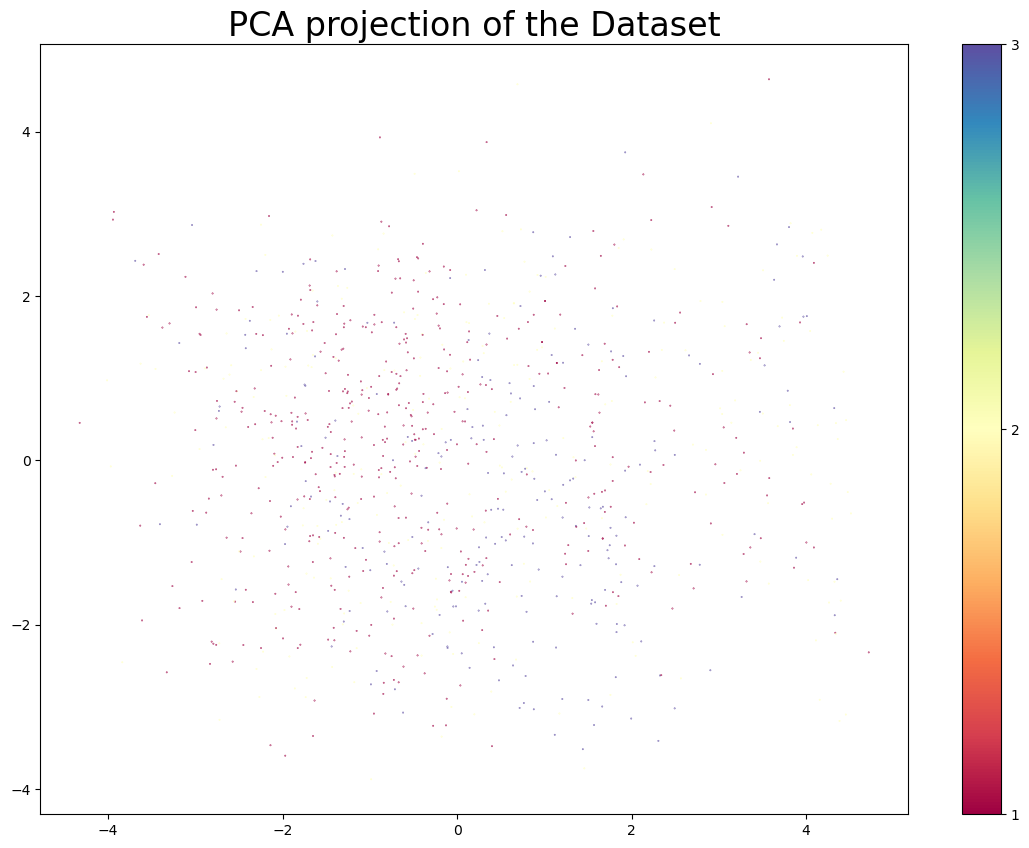

In [11]:
import pandas as pd
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt


# Assume 'Aquifer_Groups' is the column in DatatHot that contains the group labels
# Also, assume it is categorical. If not, convert it to categorical dtype
DatatNoOBS['Aquifer Group'] = DatatNoOBS['Aquifer Group'].astype('category')

# Initialize PCA object
pca = PCA(n_components=2)

# Fit the PCA model to the data and transform the data
# Exclude 'Aquifer_Groups' when fitting PCA
embedding = pca.fit_transform(DatatNoOBS.drop('Aquifer Group', axis=1))

# Create a plot
fig, ax = plt.subplots(1, figsize=(14, 10))

# Use 'Aquifer_Groups' for color coding
scatter = ax.scatter(embedding[:, 0], embedding[:, 1], s=0.1,
                     c=DatatNoOBS['Aquifer Group'].cat.codes, cmap='Spectral')

# Create a color bar
cbar = plt.colorbar(scatter, ticks=range(len(DatatNoOBS['Aquifer Group'].cat.categories)))
cbar.ax.set_yticklabels(DatatNoOBS['Aquifer Group'].cat.categories)

plt.title('PCA projection of the Dataset', fontsize=24)

plt.show()

C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:259: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_21548\3656962701.py:17: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(embedding[:, 0], embedding[:, 1], s=0.1, cmap='Spectral')


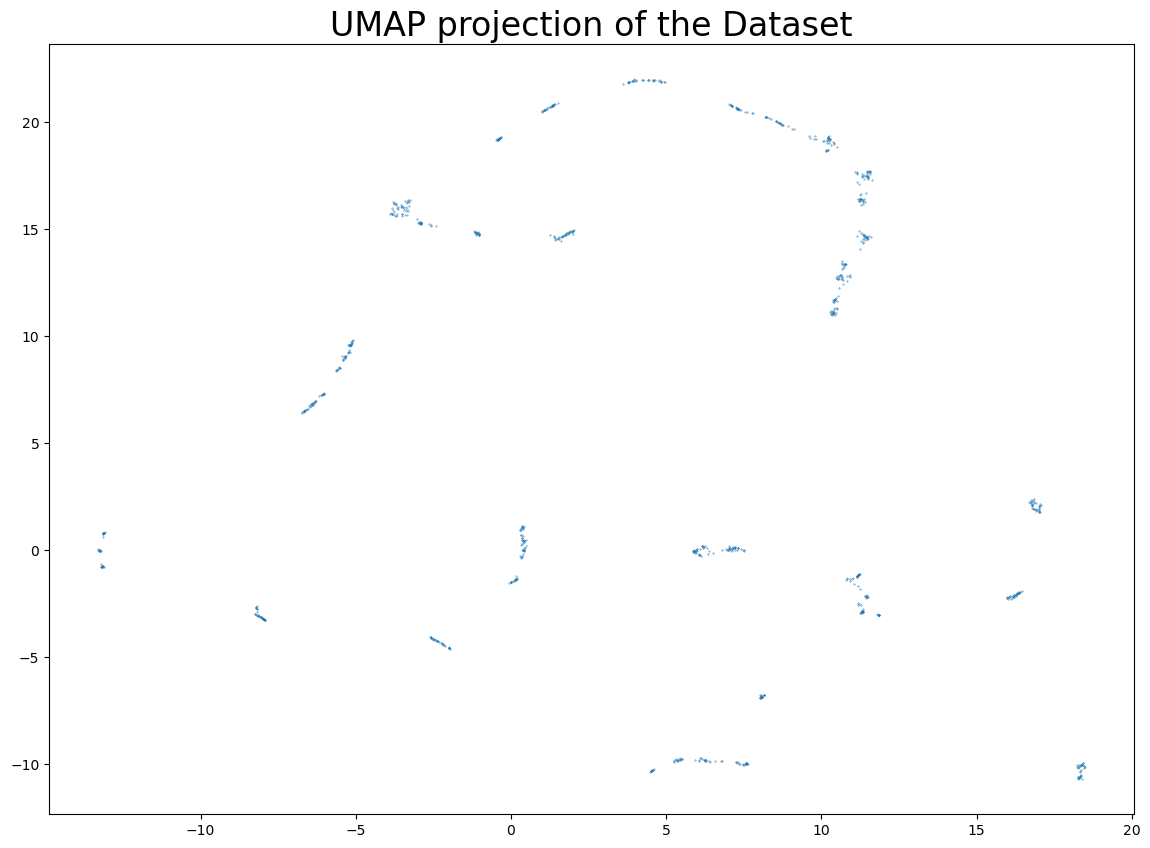

In [82]:
import umap
import umap.plot
import pandas as pd
import matplotlib.pyplot as plt

# Assume DatatHot is your DataFrame
# DatatHot = pd.read_csv("your_data.csv")

# Initialize UMAP reducer
reducer = umap.UMAP(random_state=42)

# Fit the reducer to the data and transform the data
embedding = reducer.fit_transform(DatatHot)

# Create a plot
fig, ax = plt.subplots(1, figsize=(14, 10))
plt.scatter(embedding[:, 0], embedding[:, 1], s=0.1, cmap='Spectral')
plt.title('UMAP projection of the Dataset', fontsize=24)

plt.show()

C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\spectral.py:550: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_56160\2111349658.py:21: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(u[indices,0], u[indices,1], cmap='Spectral', label=label_names[label])
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jo

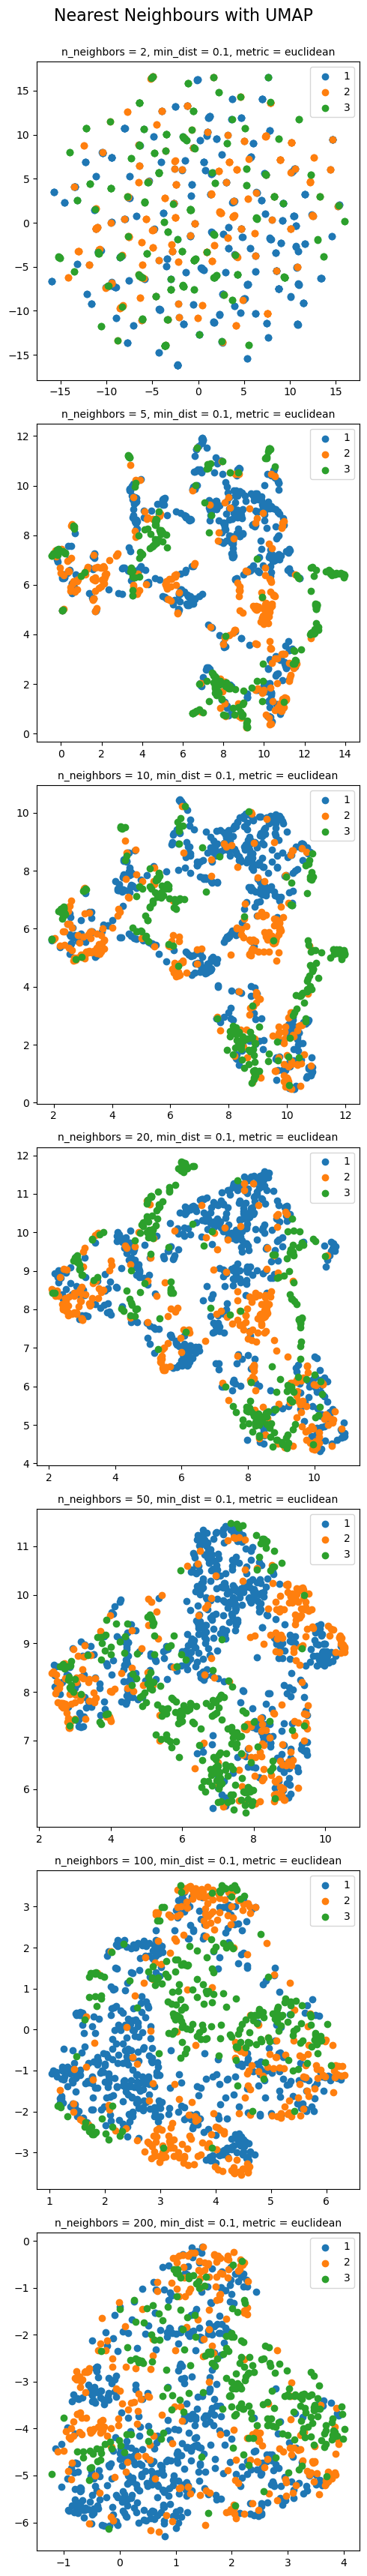

In [99]:
import matplotlib.pyplot as plt
import umap
import numpy as np
from sklearn.preprocessing import LabelEncoder

def draw_umap(n_neighbors=15, min_dist=0.1, n_components=2, metric='euclidean', random_state=42, data=None, labels=None, label_names=None, ax=None):
    fit = umap.UMAP(
        n_neighbors=n_neighbors,
        min_dist=min_dist,
        n_components=n_components,
        metric=metric,
        random_state=random_state
    )
    u = fit.fit_transform(data);

    for label in np.unique(labels):
        indices = np.where(labels == label)
        if n_components == 1:
            ax.scatter(u[indices,0], range(len(indices)), cmap='Spectral', label=label_names[label])
        elif n_components == 2:
            ax.scatter(u[indices,0], u[indices,1], cmap='Spectral', label=label_names[label])
        elif n_components == 3:
            ax = fig.add_subplot(111, projection='3d')
            ax.scatter(u[indices,0], u[indices,1], u[indices,2], cmap='Spectral', s=100, label=label_names[label])
    ax.set_title(f'n_neighbors = {n_neighbors}, min_dist = {min_dist}, metric = {metric}', fontsize=10)
    ax.legend()

# Prepare data and labels
data = DatatNoOBS.drop('Aquifer Group', axis=1)  # Assuming 'Aquifer Group' is the column you want to use for coloring

label_encoder = LabelEncoder()
labels = label_encoder.fit_transform(DatatNoOBS['Aquifer Group'])

label_names = dict(zip(range(len(label_encoder.classes_)), label_encoder.classes_))

n_neighbors_values = [2, 5, 10, 20, 50, 100, 200]

fig, axs = plt.subplots(len(n_neighbors_values), figsize=(5, 5 * len(n_neighbors_values)))

for ax, n in zip(axs, n_neighbors_values):
    draw_umap(n_neighbors=n, data=data, labels=labels, label_names=label_names, ax=ax)
    
fig.suptitle('Nearest Neighbours with UMAP', fontsize=16)  # Add a main title to the figure
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig('Figures/NNUmapfinetun.png') 
plt.show()

C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_21548\1726432658.py:21: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(u[indices,0], u[indices,1], cmap='Spectral', label=label_names[label])
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_21548\1726432658.py:21: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(u[indices,0], u[ind

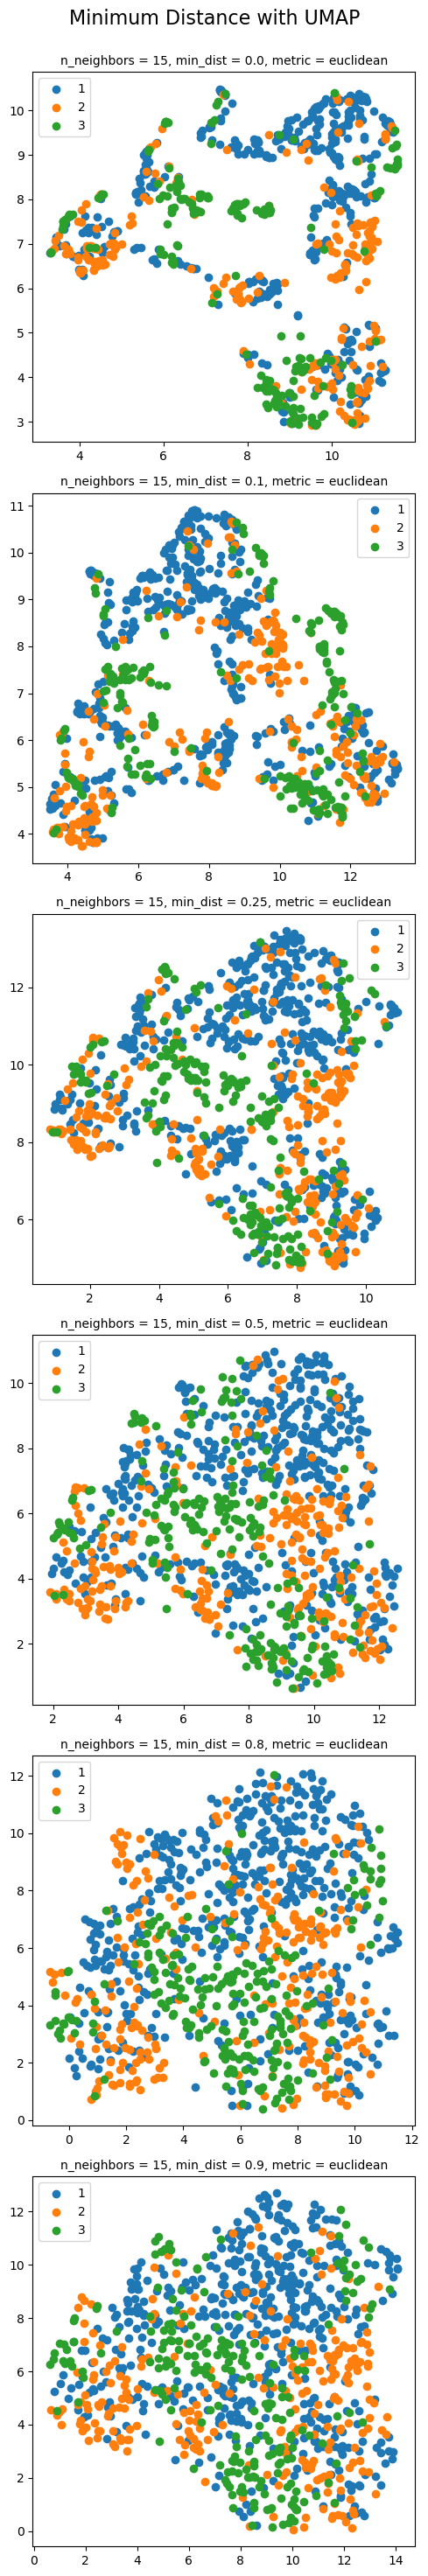

In [127]:
data = DatatNoOBS.drop('Aquifer Group', axis=1)  # Assuming 'Aquifer Group' is the column you want to use for coloring

label_encoder = LabelEncoder()
labels = label_encoder.fit_transform(DatatNoOBS['Aquifer Group'])

label_names = dict(zip(range(len(label_encoder.classes_)), label_encoder.classes_))

min_dist_values = [0.0, 0.1, 0.25, 0.5, 0.8, 0.9]

fig, axs = plt.subplots(len(min_dist_values), figsize=(5, 5 * len(min_dist_values)))

for ax, d in zip(axs, min_dist_values):
    draw_umap(min_dist=d, data=data, labels=labels, label_names=label_names, ax=ax)
    
fig.suptitle('Minimum Distance with UMAP', fontsize=16)  # Add a main title to the figure
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig('Figures/MinDisUmapfinetun.png') 
plt.show()


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_21548\1264462280.py:19: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(u[indices,0], range(len(indices[0])), cmap='Spectral', label=label_names[label])
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_21548\1264462280.py:21: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(u[indices

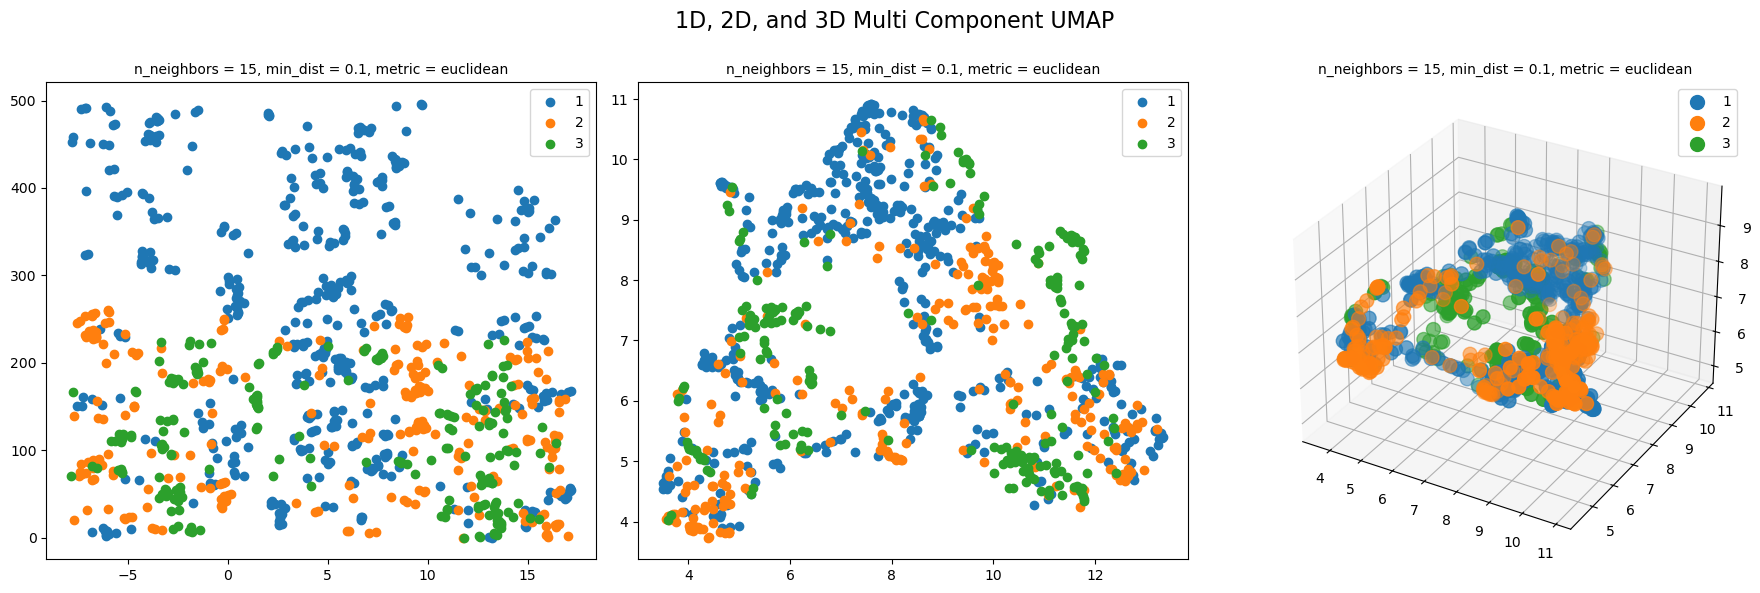

In [153]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import LabelEncoder
import umap

def draw_umap3D(n_neighbors=15, min_dist=0.1, n_components=2, metric='euclidean', random_state=42, data=None, labels=None, label_names=None, ax=None):
    fit = umap.UMAP(
        n_neighbors=n_neighbors,
        min_dist=min_dist,
        n_components=n_components,
        metric=metric,
        random_state=random_state
    )
    u = fit.fit_transform(data);

    for label in np.unique(labels):
        indices = np.where(labels == label)
        if n_components == 1:
            ax.scatter(u[indices,0], range(len(indices[0])), cmap='Spectral', label=label_names[label])
        elif n_components == 2:
            ax.scatter(u[indices,0], u[indices,1], cmap='Spectral', label=label_names[label])
        elif n_components == 3:
            ax.scatter(u[indices,0], u[indices,1], u[indices,2], cmap='Spectral', s=100, label=label_names[label])
    ax.set_title(f'n_neighbors = {n_neighbors}, min_dist = {min_dist}, metric = {metric}', fontsize=10)
    ax.legend()

# your data preparation code here
data = DatatNoOBS.drop('Aquifer Group', axis=1)  # Assuming 'Aquifer Group' is the column you want to use for coloring

label_encoder = LabelEncoder()
labels = label_encoder.fit_transform(DatatNoOBS['Aquifer Group'])

label_names = dict(zip(range(len(label_encoder.classes_)), label_encoder.classes_))

# List of components
n_components_list = [1, 2, 3]

# Create a new figure
fig = plt.figure(figsize=(18, 6))  # Adjust size to your preference

# Loop over components
for i, n_components in enumerate(n_components_list, start=1):
    # 3D plots require a different type of subplot
    if n_components == 3:
        ax = fig.add_subplot(1, 3, i, projection='3d')
    else:
        ax = fig.add_subplot(1, 3, i)
    
    # Call draw_umap
    draw_umap3D(n_neighbors=15, min_dist=0.1, n_components=n_components, metric='euclidean', 
              random_state=42, data=data, labels=labels, label_names=label_names, ax=ax)

# Show the plot
fig.suptitle('1D, 2D, and 3D Multi Component UMAP', fontsize=16)  # Add a main title to the figure
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig('Figures/UMAP123D.png')
plt.show()

C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_21548\1726432658.py:21: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(u[indices,0], u[indices,1], cmap='Spectral', label=label_names[label])
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_21548\1726432658.py:21: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(u[indices,0], u[ind

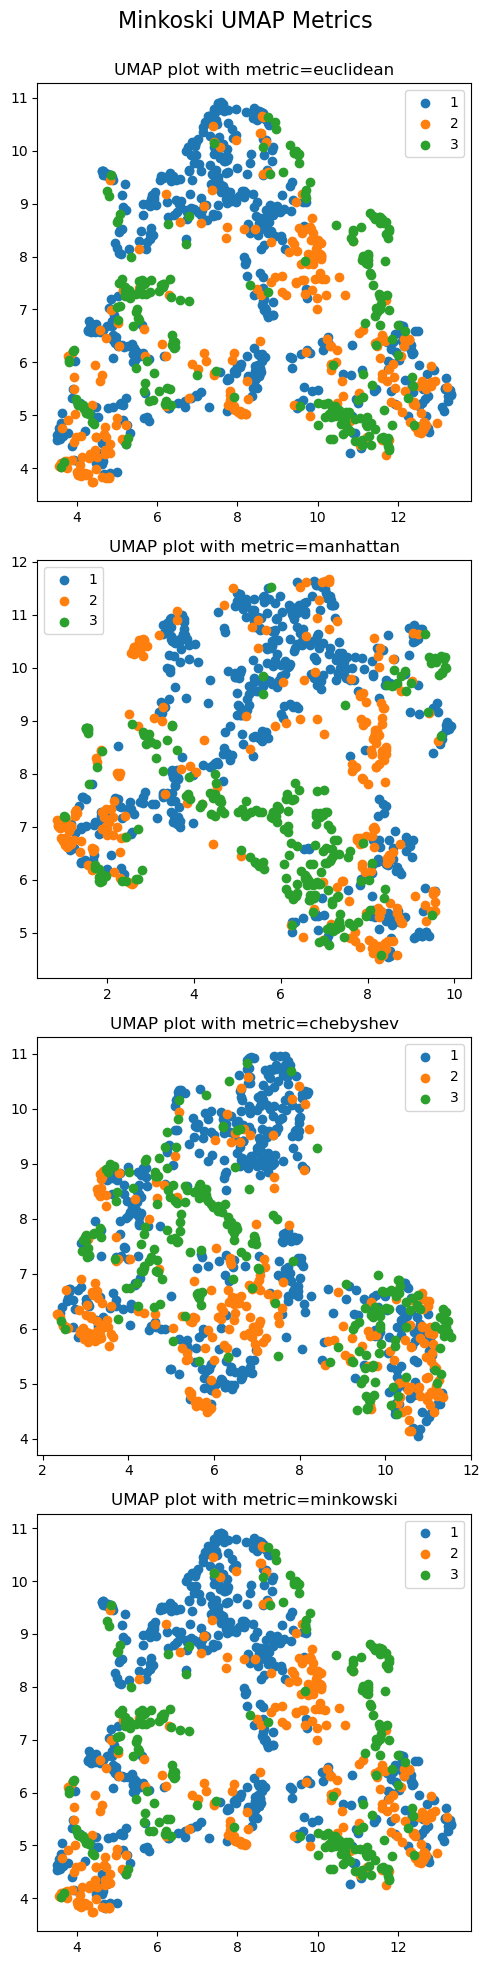

In [132]:
import matplotlib.pyplot as plt
import numpy as np

data = DatatNoOBS.drop('Aquifer Group', axis=1)  # Assuming 'Aquifer Group' is the column you want to use for coloring

label_encoder = LabelEncoder()
labels = label_encoder.fit_transform(DatatNoOBS['Aquifer Group'])

metrics = ['euclidean', 'manhattan', 'chebyshev', 'minkowski']
n_metrics = len(metrics)

# Create a single figure with multiple subplots
fig, axes = plt.subplots(n_metrics, 1, figsize=(5, 5 * n_metrics))

for i, metric in enumerate(metrics):
    # Use the ith subplot
    ax = axes[i]
    draw_umap(n_neighbors=15, min_dist=0.1, n_components=2, metric=metric, random_state=42, 
              data=data, labels=labels, label_names=label_names, ax=ax)
    ax.set_title(f'UMAP plot with metric={metric}')

# Show the plot
fig.suptitle('Minkoski UMAP Metrics', fontsize=16)  # Add a main title to the figure
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig('Figures/UMAPMinkoski.png') 

C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:575: RuntimeWarning: overflow encountered in cast
  knn_dists = knn_dists.astype(np.float32)
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_21548\1726432658.py:21: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(u[indices,0], u[indices,1], cmap='Spectral', label=label_names[label])
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site

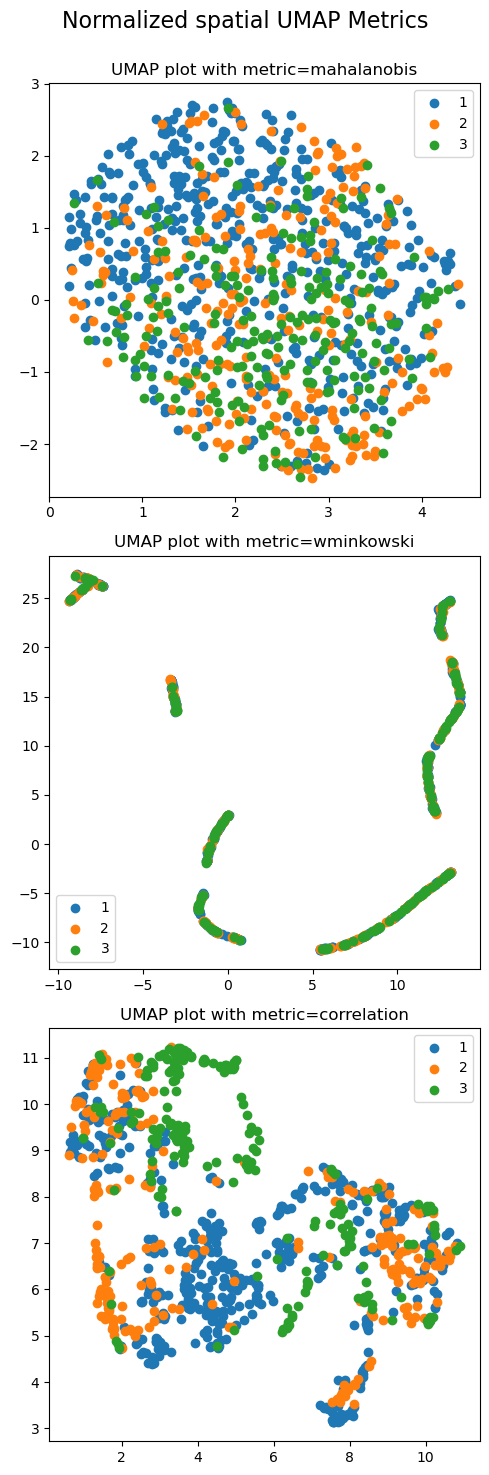

In [135]:
data = DatatNoOBS.drop('Aquifer Group', axis=1)  # Assuming 'Aquifer Group' is the column you want to use for coloring

label_encoder = LabelEncoder()
labels = label_encoder.fit_transform(DatatNoOBS['Aquifer Group'])

metrics = ['mahalanobis', 'wminkowski', 'correlation']
n_metrics = len(metrics)

# Create a single figure with multiple subplots
fig, axes = plt.subplots(n_metrics, 1, figsize=(5, 5 * n_metrics))

for i, metric in enumerate(metrics):
    # Use the ith subplot
    ax = axes[i]
    draw_umap(n_neighbors=15, min_dist=0.1, n_components=2, metric=metric, random_state=42, 
              data=data, labels=labels, label_names=label_names, ax=ax)
    ax.set_title(f'UMAP plot with metric={metric}')

# Show the plot
fig.suptitle('Normalized spatial UMAP Metrics', fontsize=16)  # Add a main title to the figure
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig('Figures/UMAPNormalSpatial.png') 

C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


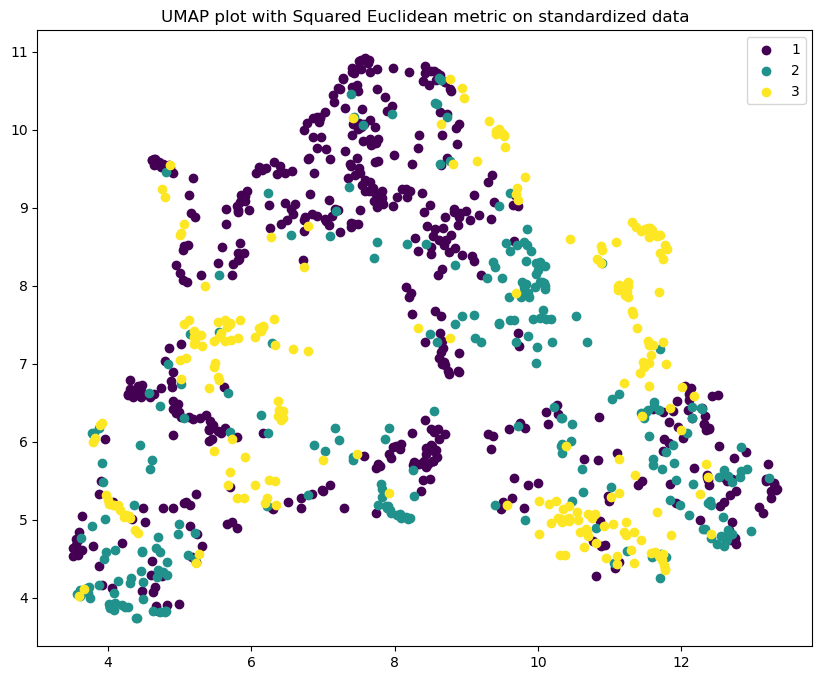

<Figure size 640x480 with 0 Axes>

In [141]:
import numpy as np
import umap
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from sklearn.preprocessing import StandardScaler

# Standardize data
scaler = StandardScaler()
data_std = scaler.fit_transform(data)

# Use 'euclidean' with the standardized data
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42, 
                    metric='euclidean')
embedding = reducer.fit_transform(data_std)

# Add 1 to labels
labels_adj = labels + 1

# Assume labels_adj are integer class labels
unique_labels = np.unique(labels_adj)
colors = [plt.cm.viridis(each) for each in np.linspace(0, 1, len(unique_labels))]

plt.figure(figsize=(10, 8))
for (label, color) in zip(unique_labels, colors):
    indices = labels_adj == label
    plt.scatter(embedding[indices, 0], embedding[indices, 1], c=np.array(color).reshape(1, -1), label=label)

plt.legend()
plt.title('UMAP plot with Squared Euclidean metric on standardized data')
plt.show()
plt.savefig('Figures/UMAPSquaredEuclidean.png') 

In [60]:
#do haversine later
DatatSWI =Datawithtime[(Datawithtime['Chlrid:D'] > 150) | (Datawithtime['Specific Conductance'] > 100)]
DatatDrought = Datawithtime[(Datawithtime['FD'] < 0)]
DatatFlood = Datawithtime[(Datawithtime['FD'] > 0)]
DatatHW = Datawithtime[(Datawithtime['HW'] > 0)]
DatatMT = Datawithtime[(Datawithtime['MT'] > 0)]

DatatLatLong = Datawithtime.copy()
                                                           
cleaned_dataset_array2 = replace_outliers_with_iqr(DatatLatLong[numeric_cols1], 1.5)
DatatLatLong[numeric_cols1] = cleaned_dataset_array2
DatatLatLong[cols_to_transform] = pt.fit_transform(DatatLatLong[cols_to_transform])  
                                                           
#numeric_cols1 = ['pH', 'As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Specific Conductance', 'Sulfat:D', 'K--T',  'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT']
cleaned_dataset_array2i = replace_outliers_with_iqr(DatatSWI[numeric_cols1], 1.5)
DatatSWI[numeric_cols1] = cleaned_dataset_array2i
DatatSWI[cols_to_transform] = pt.fit_transform(DatatSWI[cols_to_transform])

cleaned_dataset_array2ii = replace_outliers_with_iqr(DatatDrought[numeric_cols1], 1.5)
DatatDrought[numeric_cols1] = cleaned_dataset_array2ii
DatatDrought[cols_to_transform] = pt.fit_transform(DatatDrought[cols_to_transform])
                                                           
cleaned_dataset_array2iii = replace_outliers_with_iqr(DatatFlood[numeric_cols1], 1.5)
DatatFlood[numeric_cols1] = cleaned_dataset_array2iii
DatatFlood[cols_to_transform] = pt.fit_transform(DatatFlood[cols_to_transform])

cleaned_dataset_array2iv = replace_outliers_with_iqr(DatatHW[numeric_cols1], 1.5)
DatatHW[numeric_cols1] = cleaned_dataset_array2iv
DatatHW[cols_to_transform] = pt.fit_transform(DatatHW[cols_to_transform])

cleaned_dataset_array2iv = replace_outliers_with_iqr(DatatHW[numeric_cols1], 1.5)
DatatHW[numeric_cols1] = cleaned_dataset_array2iv
DatatHW[cols_to_transform] = pt.fit_transform(DatatHW[cols_to_transform])

cleaned_dataset_array2v = replace_outliers_with_iqr(DatatMT[numeric_cols1], 1.5)
DatatMT[numeric_cols1] = cleaned_dataset_array2v
DatatMT[cols_to_transform] = pt.fit_transform(DatatMT[cols_to_transform])


C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_56160\996595137.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DatatSWI[numeric_cols1] = cleaned_dataset_array2i
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_56160\996595137.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DatatSWI[cols_to_transform] = pt.fit_transform(DatatSWI[cols_to_transform])
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_56160\996595137.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slic

In [61]:
DatatLatLong.columns

Index(['OBSWELL', 'LONGITUDE', 'LATITUTE', 'DATE', 'As-T', 'Ca-T', 'Chlrid:D',
       'Fe-T', 'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Specific Conductance',
       'Sulfat:D', 'pH', 'K--T', 'U--T', 'year_month', 'PRECIPITATION',
       'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT', 'Aquifer Group'],
      dtype='object')

In [62]:
DropDF2a = ['DATE', 'year_month','OBSWell']

DatatSWILL= DatatSWI.drop(DropDF2a, axis=1, errors='ignore')
DatatDroughtLL= DatatDrought.drop(DropDF2a, axis=1, errors='ignore')
DatatFloodLL= DatatFlood.drop(DropDF2a, axis=1, errors='ignore')
DatatHWLL= DatatHW.drop(DropDF2a, axis=1, errors='ignore')
DatatMTLL= DatatMT.drop(DropDF2a, axis=1, errors='ignore')
DatatLatLong=DatatLatLong.drop(DropDF2a, axis=1, errors='ignore')

#one_hot_df = pd.get_dummies(DatatHot['Aquifer Group'], prefix='Aquifer')
#DatatHot = pd.concat([DatatHot, one_hot_df], axis=1)
#DatatHot.drop(columns='Aquifer Group', inplace=True)
#DatatHot.head()

C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_56160\2111349658.py:21: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(u[indices,0], u[indices,1], cmap='Spectral', label=label_names[label])


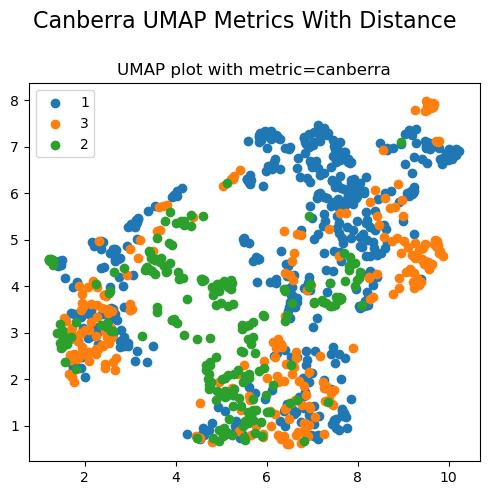

In [63]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt

data = DatatLatLong.drop('Aquifer Group', axis=1)  # Assuming 'Aquifer Group' is the column you want to use for coloring

label_encoder = LabelEncoder()
labels = label_encoder.fit_transform(DatatNoOBS['Aquifer Group'])

label_names = DatatNoOBS['Aquifer Group'].unique()

metrics = ['canberra']
n_metrics = len(metrics)

# Create a single figure with multiple subplots
fig, axes = plt.subplots(n_metrics, 1, figsize=(5, 5 * n_metrics))

for i, metric in enumerate(metrics):
    # Use the ith subplot
    ax = axes[i] if n_metrics > 1 else axes
    draw_umap(n_neighbors=15, min_dist=0.1, n_components=2, metric=metric, random_state=42, 
              data=data, labels=labels, label_names=label_names, ax=ax)
    ax.set_title(f'UMAP plot with metric={metric}')

# Show the plot
fig.suptitle('Canberra UMAP Metrics With Distance', fontsize=16)  # Add a main title to the figure
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig('Figures/UMAPcanberralatlong.png')

In [ ]:
'''
import matplotlib.pyplot as plt
import numpy as np

data = DatatLatLong.drop('Aquifer Group', axis=1)  # Assuming 'Aquifer Group' is the column you want to use for coloring

label_encoder = LabelEncoder()
labels = label_encoder.fit_transform(DatatNoOBS['Aquifer Group'])

metrics = ['canberra']
n_metrics = len(metrics)

# Create a single figure with multiple subplots
fig, axes = plt.subplots(n_metrics, 1, figsize=(5, 5 * n_metrics))

for i, metric in enumerate(metrics):
    # Use the ith subplot
    ax = axes[i] if n_metrics > 1 else axes
    draw_umap(n_neighbors=15, min_dist=0.1, n_components=2, metric=metric, random_state=42, 
              data=data, labels=labels, label_names=label_names, ax=ax)
    ax.set_title(f'UMAP plot with metric={metric}')

# Show the plot
fig.suptitle('Canberra UMAP Metrics With Distance', fontsize=16)  # Add a main title to the figure
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig('Figures/UMAPcanberralatlong.png')
'''

In [ ]:
'''
SWI, Drought, Flood, Heatwave Umaps
'''

C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_56160\2111349658.py:21: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(u[indices,0], u[indices,1], cmap='Spectral', label=label_names[label])
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_56160\2111349658.py:21: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(u[indices,0], u[ind

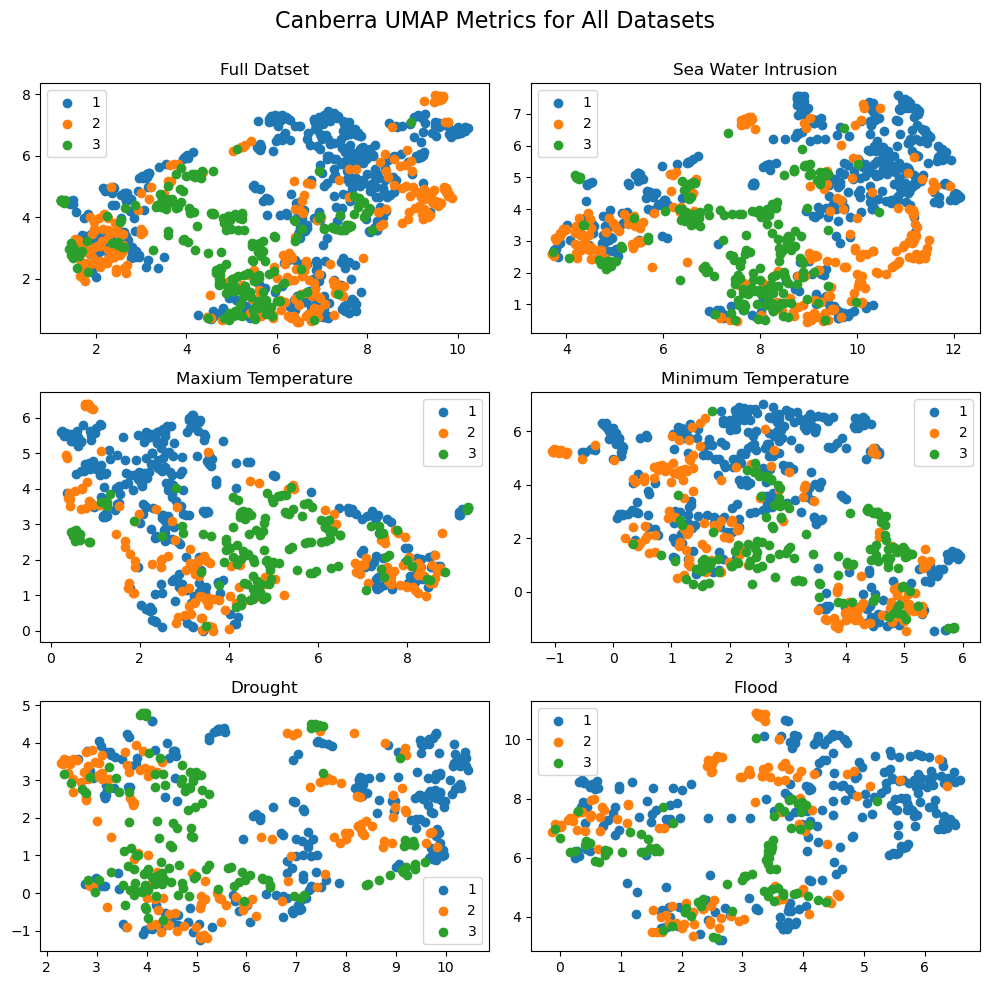

In [104]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder


# Load your four datasets
datasets = [DatatLatLong, DatatSWILL, DatatHWLL, DatatMTLL, DatatDroughtLL, DatatFloodLL]

# Initialize LabelEncoder
label_encoder = LabelEncoder()


# Create a 2x2 grid of subplots
fig, axes = plt.subplots(3, 2, figsize=(10, 10))

# List of title strings for each dataset
titles = ['Full Datset', 'Sea Water Intrusion','Maxium Temperature', 'Minimum Temperature', 'Drought', 'Flood']

for i, dataset in enumerate(datasets):
    # Prepare the data
    data = dataset.drop('Aquifer Group', axis=1)
    labels = label_encoder.fit_transform(dataset['Aquifer Group'])

    # Determine which subplot to use (flatten the 2x2 grid to a 1D array)
    ax = axes.flatten()[i]

    # Call draw_umap with 'canberra' metric
    draw_umap(n_neighbors=15, min_dist=0.1, n_components=2, metric='canberra', 
              random_state=42, data=data, labels=labels, label_names=label_names, ax=ax)

    # Set title for this subplot to the corresponding title from the titles list
    ax.set_title(titles[i])

# Set main title for the figure
fig.suptitle('Canberra UMAP Metrics for All Datasets', fontsize=16)

# Adjust layout for better appearance
plt.tight_layout(rect=[0, 0, 1, 0.98])

# Save the figure
plt.savefig('Figures/UMAPcanberraconditions.png')

In [161]:
DatatLatLong.columns

Index(['LONGITUDE', 'LATITUTE', 'As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T',
       'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'K--T', 'U--T',
       'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT',
       'Aquifer Group'],
      dtype='object')

In [102]:
DropDF3a = ['LONGITUDE', 'LATITUTE', 'DATE', 'year_month', 'OBSWELL']
DatatSWIND= DatatSWI.drop(DropDF3a, axis=1, errors='ignore')
DatatDroughtND= DatatDrought.drop(DropDF3a, axis=1, errors='ignore')
DatatFloodND= DatatFlood.drop(DropDF3a, axis=1, errors='ignore')
DatatHWND= DatatHW.drop(DropDF3a, axis=1, errors='ignore')
DatatMTND=DatatMT.drop(DropDF3a, axis=1, errors='ignore')
DatatLLNDAgain = DatatLatLong.drop(DropDF3a, axis=1, errors='ignore')
DatatSWIND.head()

,As-T,Ca-T,Chlrid:D,Fe-T,Mn-T,N.Kjel:T,P--T,Pb-T,Specific Conductance,Sulfat:D,pH,K--T,U--T,PRECIPITATION,MIN_TEMP,MAX_TEMP,FD,HW,MT,Aquifer Group
0,1.703764,1.810173,1.508307,1.133667,0.321408,0.609752,0.832238,1.683497,1.612400,0.917091,0.626079,-2.246694,-0.779889,-0.039903,0.526548,0.905487,0.588046,-2.753433,-1.261631,1
1,1.703764,1.810173,1.508307,1.358161,0.444986,-1.230267,0.991040,1.683497,1.522207,1.014125,-0.128973,1.690795,-0.779889,-0.321895,0.957947,1.440422,-0.052500,-0.599681,-0.195816,1
2,1.130863,1.810173,1.508307,1.425713,0.454804,0.411569,0.926023,-0.542198,1.612400,0.959954,0.626079,1.690795,1.054876,-0.152328,-0.043965,0.822657,0.265002,1.096363,0.342577,1
3,1.165571,1.810173,1.508307,1.238074,0.320332,0.178364,0.914756,-0.679473,1.612400,0.922528,0.271609,1.690795,1.121371,0.588713,-0.655668,-0.510546,1.602651,-0.129141,1.104692,1
4,0.969380,1.810173,1.508307,0.776925,0.305181,0.046285,0.427899,-0.684914,1.555804,1.083002,0.271609,1.690795,0.921546,-0.323887,0.980144,1.708572,0.221618,0.692780,0.234201,1


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_56160\2111349658.py:21: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(u[indices,0], u[indices,1], cmap='Spectral', label=label_names[label])
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_56160\2111349658.py:21: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(u[indices,0], u[ind

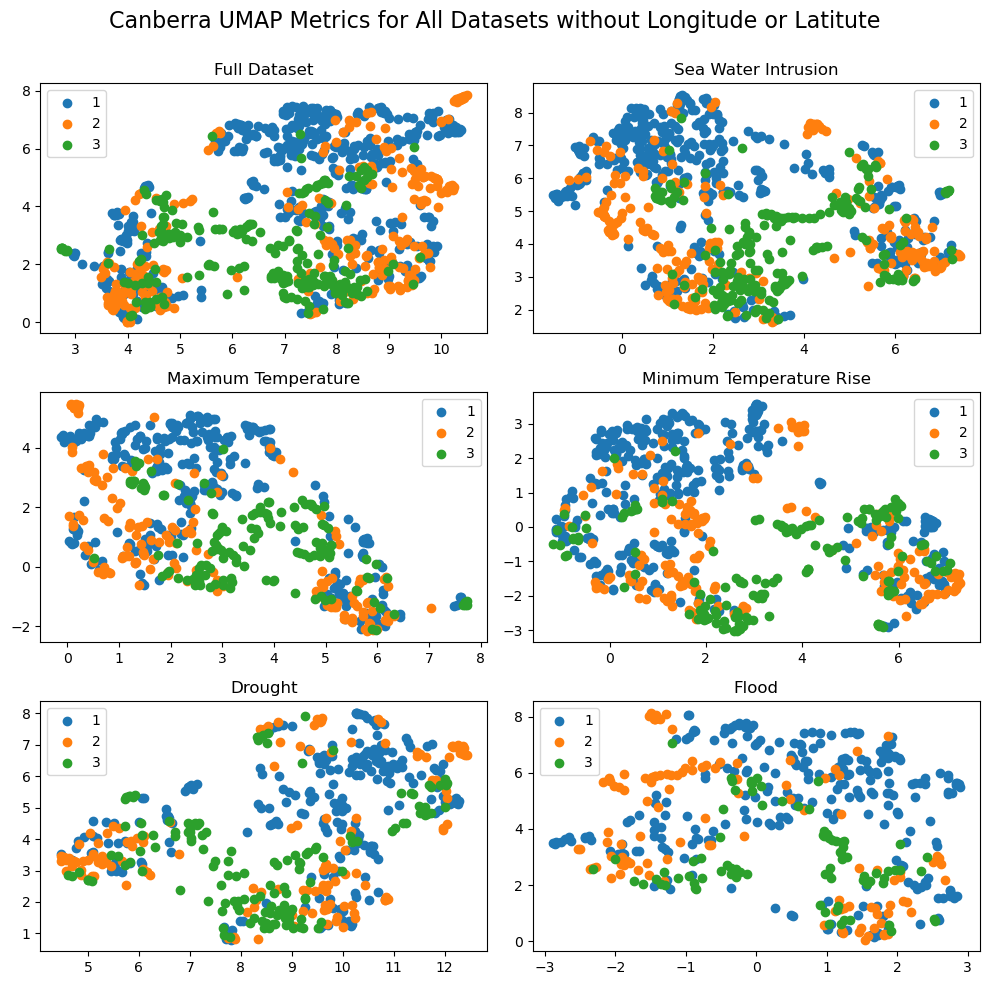

In [105]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

# Load your four datasets
datasets = [DatatLLNDAgain, DatatSWIND, DatatHWND, DatatMTND, DatatDroughtND, DatatFloodND]

# Initialize LabelEncoder
label_encoder = LabelEncoder()

# Create a 2x2 grid of subplots
fig, axes = plt.subplots(3, 2, figsize=(10, 10))

# List of title strings for each dataset
titles = ['Full Dataset', 'Sea Water Intrusion','Maximum Temperature','Minimum Temperature Rise', 'Drought', 'Flood']


for i, dataset in enumerate(datasets):
    # Prepare the data
    data = dataset.drop('Aquifer Group', axis=1)
    labels = label_encoder.fit_transform(dataset['Aquifer Group'])

    # Determine which subplot to use (flatten the 2x2 grid to a 1D array)
    ax = axes.flatten()[i]

    # Call draw_umap with 'canberra' metric
    draw_umap(n_neighbors=15, min_dist=0.1, n_components=2, metric='canberra', 
              random_state=42, data=data, labels=labels, label_names=label_names, ax=ax)

    # Set title for this subplot to the corresponding title from the titles list
    ax.set_title(titles[i])

# Set main title for the figure
fig.suptitle('Canberra UMAP Metrics for All Datasets without Longitude or Latitute', fontsize=16)

# Adjust layout for better appearance
plt.tight_layout(rect=[0, 0, 1, 0.98])

# Save the figure
plt.savefig('Figures/UMAPcanberraconditionsND.png')

In [ ]:
'''
Supervised Umap

Source: 
https://www.kaggle.com/code/bextuychiev/beautiful-umap-tutorial-on-100-dimensional-data

'''

In [69]:
DropDF4a = ['OBSWELL']
DataHOTNOOBS= DatatHot.drop(DropDF4a, axis=1, errors='ignore')

DropDF4b = ['As-T', 'Mn-T', 'Pb-T', 'U--T']
Xdata = DataHOTNOOBS.drop(DropDF4b, axis=1, errors='ignore')
Ya = DataHOTNOOBS['As-T']
Ym = DataHOTNOOBS['Mn-T']
Yp = DataHOTNOOBS['Pb-T']
Yu = DataHOTNOOBS['U--T']

C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.


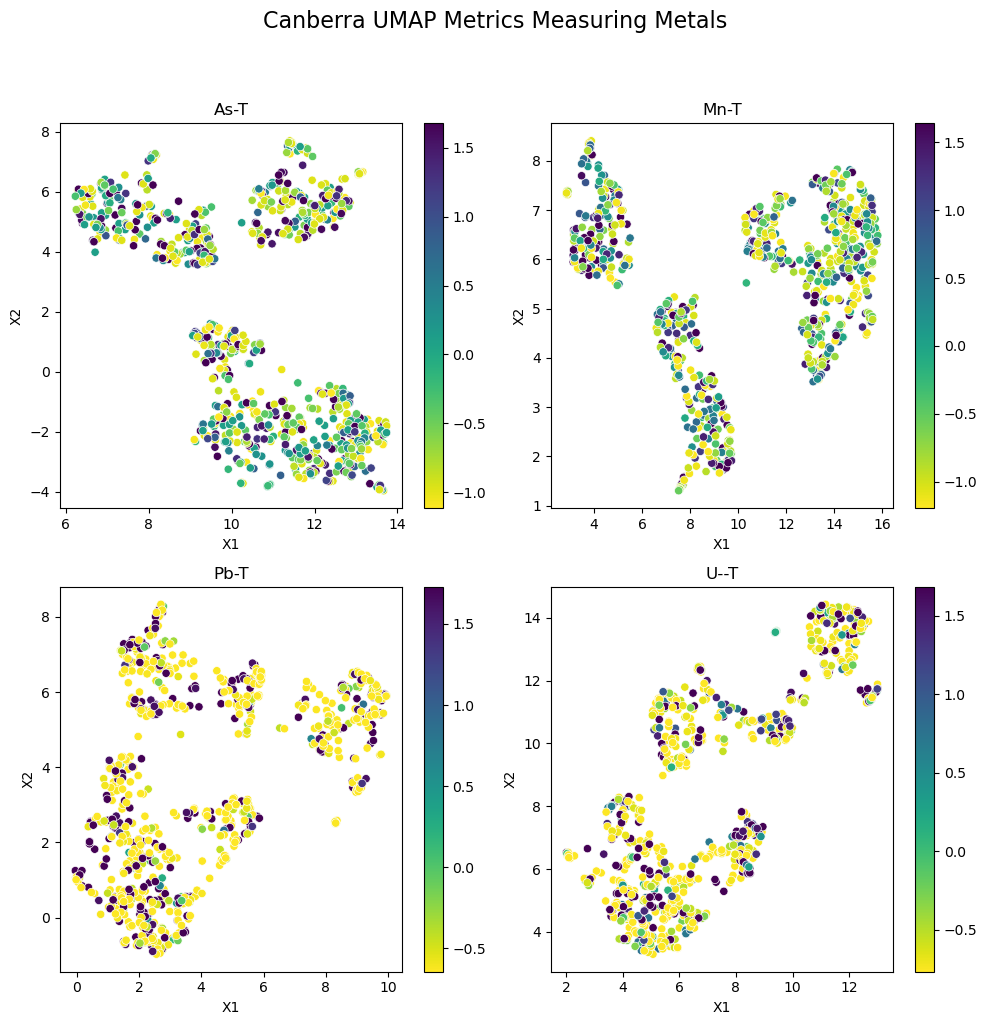

<Figure size 640x480 with 0 Axes>

In [109]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd

def supervised_umap(X, Y_list, titles):
    fig, axs = plt.subplots(2, 2, figsize=(10, 10))  # create a 2x2 grid of subplots
    axs = axs.ravel()  # flatten the grid to easily iterate over it

    for i, Y in enumerate(Y_list):
        manifold = umap.UMAP(
            n_neighbors=15,
            n_components=2,
            metric='canberra',
            low_memory=True,
            random_state=42
        ).fit(
            X = X,
            y = Y
        )
        ReducedX = manifold.transform(X)

        # normalize Y values to range [0, 1] for using with the colormap
        norm = mcolors.Normalize(vmin=np.min(Y), vmax=np.max(Y))

        # create a colormap
        cmap = plt.cm.viridis_r

        # Create a dataframe for seaborn
        data = pd.DataFrame(ReducedX, columns=['X1', 'X2'])
        data['Y'] = Y

        # Use seaborn to create the scatterplot
        ax = sns.scatterplot(x='X1', y='X2', hue='Y', palette=cmap, data=data, ax=axs[i], legend=False)

        # Add a colorbar using matplotlib
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])  # necessary for the colorbar
        fig.colorbar(sm, ax=axs[i])

        # Set the title for this subplot
        axs[i].set_title(titles[i])

    plt.tight_layout()
    return fig  # return the figure object

# Call your function with appropriate parameters
Y_list = [Ya, Ym, Yp, Yu]  # replace with your actual Y values
titles = ['As-T', 'Mn-T', 'Pb-T', 'U--T']  # replace with your actual titles

# Call the function and get the returned figure object
fig = supervised_umap(X=Xdata, Y_list=Y_list, titles=titles)

# Set main title for the figure
fig.suptitle('Canberra UMAP Metrics Measuring Metals', fontsize=16, y=1.02)  # Adjust 'y' for title position

# Adjust layout for better appearance
plt.tight_layout(rect=[0, 0, 1, 0.98])

plt.show()

# Save the figure
plt.savefig('Figures/UMAPmetalscamp.png')

In [110]:
one_hot_dfa = pd.get_dummies(DatatSWIND['Aquifer Group'], prefix='Aquifer')
DatatSWINDHot = pd.concat([DatatSWIND, one_hot_dfa], axis=1)
DatatSWINDHot.drop(columns='Aquifer Group', inplace=True)

one_hot_dfb = pd.get_dummies(DatatDroughtND['Aquifer Group'], prefix='Aquifer')
DatatDroughtNDHot = pd.concat([DatatDroughtND, one_hot_dfb], axis=1)
DatatDroughtNDHot.drop(columns='Aquifer Group', inplace=True)

one_hot_dfc = pd.get_dummies(DatatFloodND['Aquifer Group'], prefix='Aquifer')
DatatFloodNDHot = pd.concat([DatatFloodND, one_hot_dfc], axis=1)
DatatFloodNDHot.drop(columns='Aquifer Group', inplace=True)

one_hot_dfd = pd.get_dummies(DatatHWND['Aquifer Group'], prefix='Aquifer')
DatatHWNDHot = pd.concat([DatatHWND, one_hot_dfd], axis=1)
DatatHWNDHot.drop(columns='Aquifer Group', inplace=True)

one_hot_dfe = pd.get_dummies(DatatMTND['Aquifer Group'], prefix='Aquifer')
DatatMTNDHot = pd.concat([DatatMTND, one_hot_dfd], axis=1)
DatatMTNDHot.drop(columns='Aquifer Group', inplace=True)

In [111]:
#DropDF4b = ['As-T', 'Mn-T', 'Pb-T', 'U--T']
Xdataswi = DatatSWINDHot.drop(DropDF4b, axis=1, errors='ignore')
Yaswi = DatatSWINDHot['As-T']
Ymswi = DatatSWINDHot['Mn-T']
Ypswi = DatatSWINDHot['Pb-T']
Yuswi = DatatSWINDHot['U--T']

XdataDrought = DatatDroughtNDHot.drop(DropDF4b, axis=1, errors='ignore')
YaDrought = DatatDroughtNDHot['As-T']
YmDrought = DatatDroughtNDHot['Mn-T']
YpDrought = DatatDroughtNDHot['Pb-T']
YuDrought = DatatDroughtNDHot['U--T']

XdataFlood = DatatFloodNDHot.drop(DropDF4b, axis=1, errors='ignore')
YaFlood = DatatFloodNDHot['As-T']
YmFlood = DatatFloodNDHot['Mn-T']
YpFlood = DatatFloodNDHot['Pb-T']
YuFlood = DatatFloodNDHot['U--T']

XdataHW = DatatHWNDHot.drop(DropDF4b, axis=1, errors='ignore')
YaHW = DatatHWNDHot['As-T']
YmHW = DatatHWNDHot['Mn-T']
YpHW = DatatHWNDHot['Pb-T']
YuHW = DatatHWNDHot['U--T']

DatatMTNDHot=DatatMTNDHot.dropna()
XdataMT = DatatMTNDHot.drop(DropDF4b, axis=1, errors='ignore')
YaMT = DatatMTNDHot['As-T']
YmMT = DatatMTNDHot['Mn-T']
YpMT = DatatMTNDHot['Pb-T']
YuMT = DatatMTNDHot['U--T']



In [112]:
# Check if there are any NaN values in your data
print('NaN values in XdataMT:', XdataMT.isna().any().any())
print('NaN values in YaMT:', YaMT.isna().any())
print('NaN values in YmMT:', YmMT.isna().any())
print('NaN values in YpMT:', YpMT.isna().any())
print('NaN values in YuMT:', YuMT.isna().any())

NaN values in XdataMT: False
NaN values in YaMT: False
NaN values in YmMT: False
NaN values in YpMT: False
NaN values in YuMT: False


In [113]:
XdataMT.head()

,Ca-T,Chlrid:D,Fe-T,N.Kjel:T,P--T,Specific Conductance,Sulfat:D,pH,K--T,PRECIPITATION,MIN_TEMP,MAX_TEMP,FD,HW,MT,Aquifer_1,Aquifer_2,Aquifer_3
2,1.789649,1.510472,1.426449,0.509726,0.965844,1.723355,1.105536,0.743535,1.710775,-0.202593,-0.177541,0.794695,0.196736,0.959474,0.055947,1.0,0.0,0.0
3,1.789649,1.510472,1.236398,0.279136,0.954692,1.723355,1.068564,0.398775,1.710775,0.495590,-0.811859,-0.564837,1.518237,-0.367716,1.009382,1.0,0.0,0.0
4,1.789649,1.510472,0.772764,0.147312,0.470554,1.723355,1.226869,0.398775,1.710775,-0.362581,0.873876,1.660568,0.152964,0.538847,-0.114629,1.0,0.0,0.0
6,1.789649,1.510472,-1.128932,0.662589,0.458701,1.723355,1.546044,0.347388,1.710775,-0.504117,-1.685115,-0.932032,0.073665,0.442449,0.208450,1.0,0.0,0.0
7,1.789649,1.510472,1.183443,0.405298,1.009196,1.723355,1.546044,0.691580,1.710775,-0.495795,1.120991,1.911991,-0.311354,1.591661,0.523755,1.0,0.0,0.0


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.


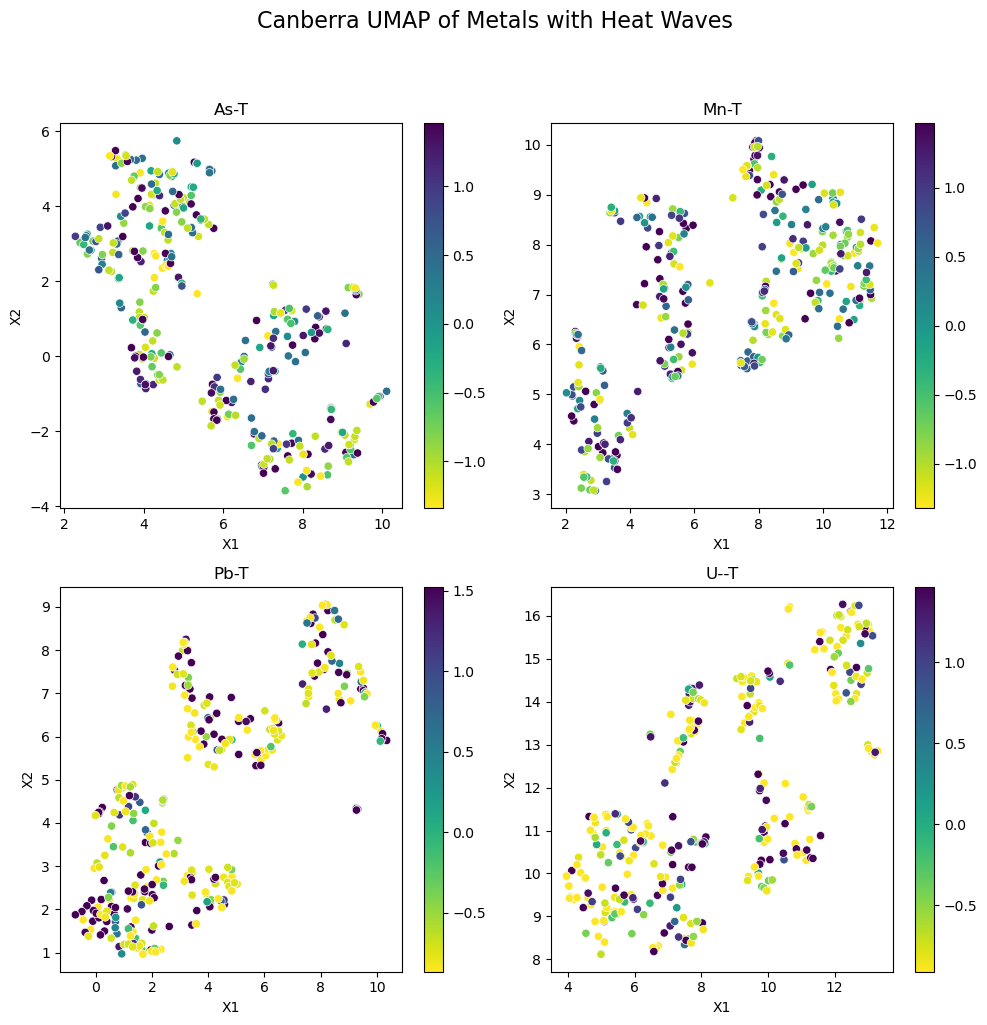

In [114]:
# Call your function with appropriate parameters
Y_listHW = [YaHW, YmHW, YpHW, YuHW]  # replace with your actual Y values
titlesHW = ['As-T', 'Mn-T', 'Pb-T', 'U--T']  # replace with your actual titles

# Call the function and get the returned figure object
figHW = supervised_umap(X=XdataHW, Y_list=Y_listHW, titles=titlesHW)
# Set main title for the figure
figHW.suptitle('Canberra UMAP of Metals with Heat Waves', fontsize=16, y=1.02)
# Adjust layout for better appearance
figHW.tight_layout(rect=[0, 0, 1, 0.98])
# Save the figure
figHW.savefig('Figures/UMAPcanberrametalsHW.png')

C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.


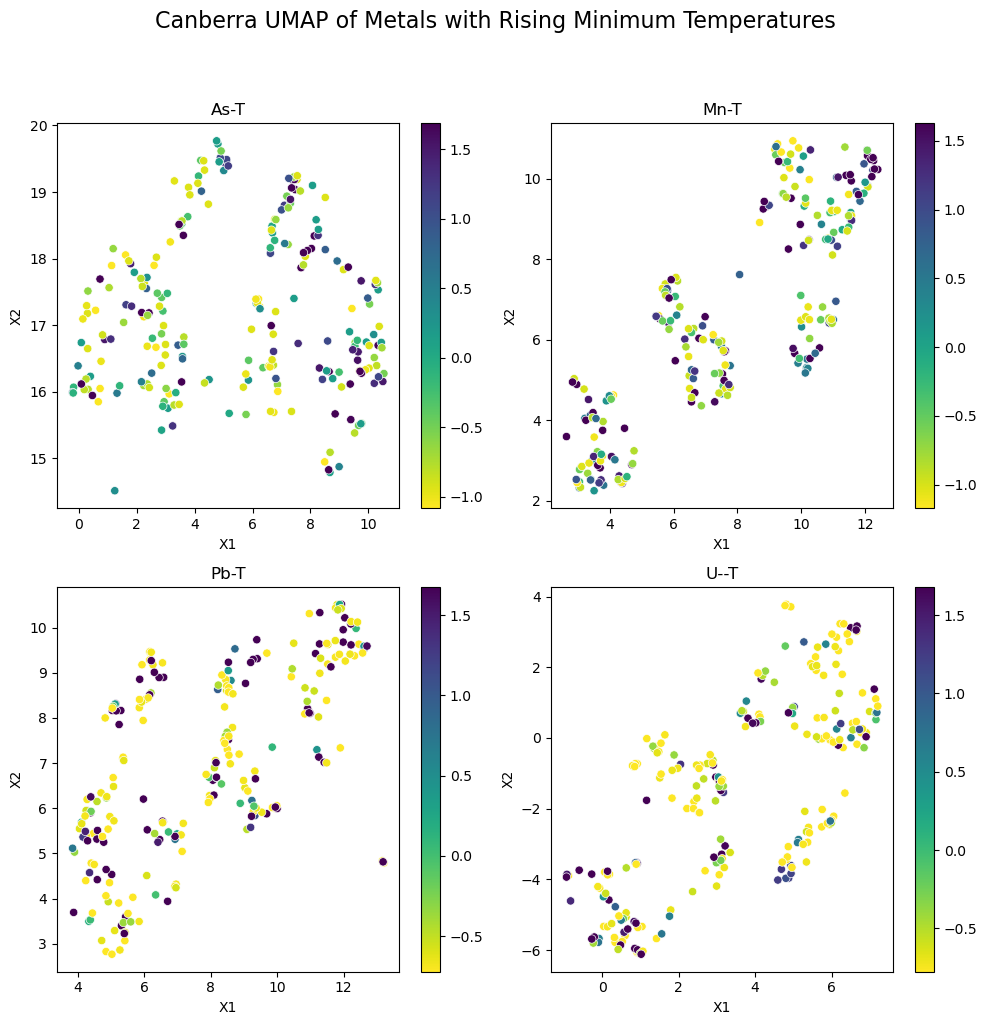

In [115]:
# Call your function with appropriate parameters
Y_listMT = [YaMT, YmMT, YpMT, YuMT]  # replace with your actual Y values
titlesMT = ['As-T', 'Mn-T', 'Pb-T', 'U--T']  # replace with your actual titles

# Call the function and get the returned figure object
figMT = supervised_umap(X=XdataMT, Y_list=Y_listMT, titles=titlesMT)
# Set main title for the figure
figMT.suptitle('Canberra UMAP of Metals with Rising Minimum Temperatures', fontsize=16, y=1.02)
# Adjust layout for better appearance
figMT.tight_layout(rect=[0, 0, 1, 0.98])
# Save the figure
figMT.savefig('Figures/UMAPcanberrametalsMT.png')

C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.


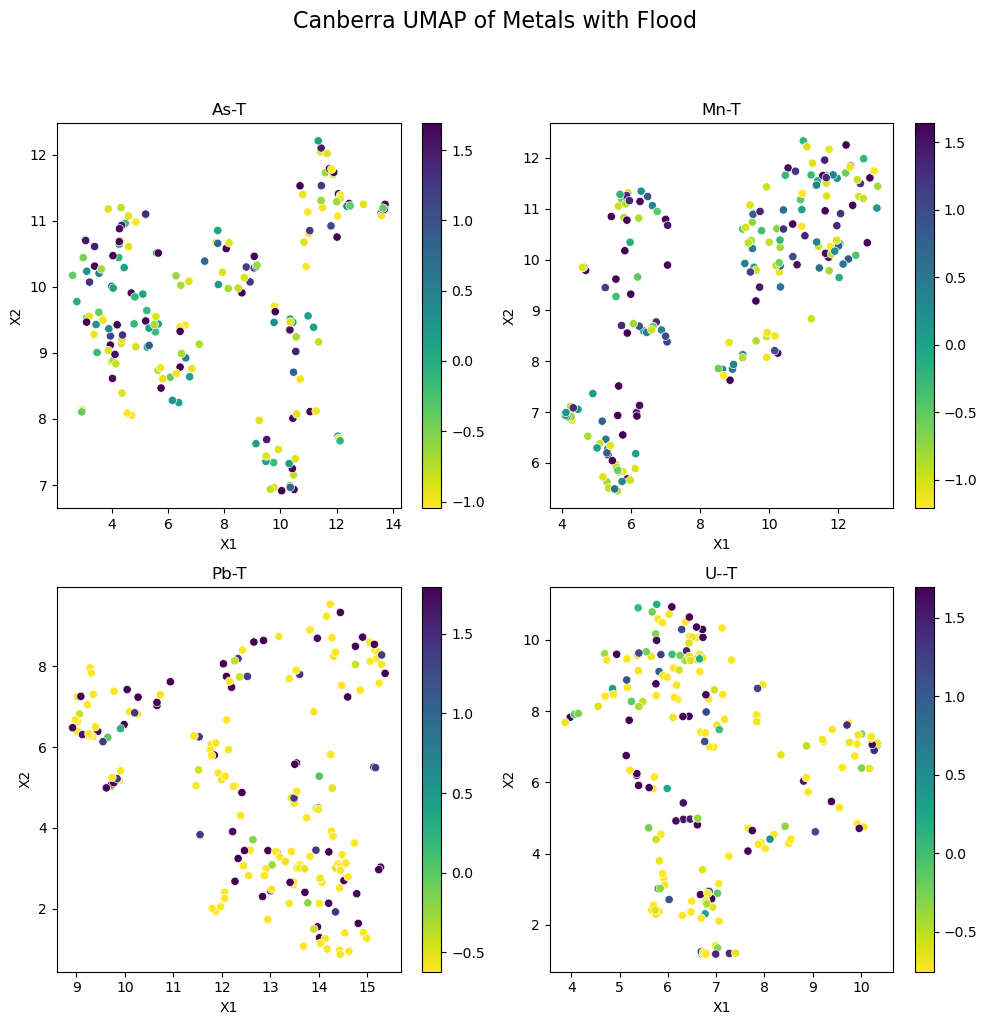

In [116]:
# Call your function with appropriate parameters
Y_listFlood = [YaFlood, YmFlood, YpFlood, YuFlood]  # replace with your actual Y values
titlesFlood = ['As-T', 'Mn-T', 'Pb-T', 'U--T']  # replace with your actual titles

# Call the function and get the returned figure object
figFlood = supervised_umap(X=XdataFlood, Y_list=Y_listFlood, titles=titlesFlood)
# Set main title for the figure
figFlood.suptitle('Canberra UMAP of Metals with Flood', fontsize=16, y=1.02)
# Adjust layout for better appearance
figFlood.tight_layout(rect=[0, 0, 1, 0.98])
# Save the figure
figFlood.savefig('Figures/UMAPcanberrametalsFlood.png')


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.


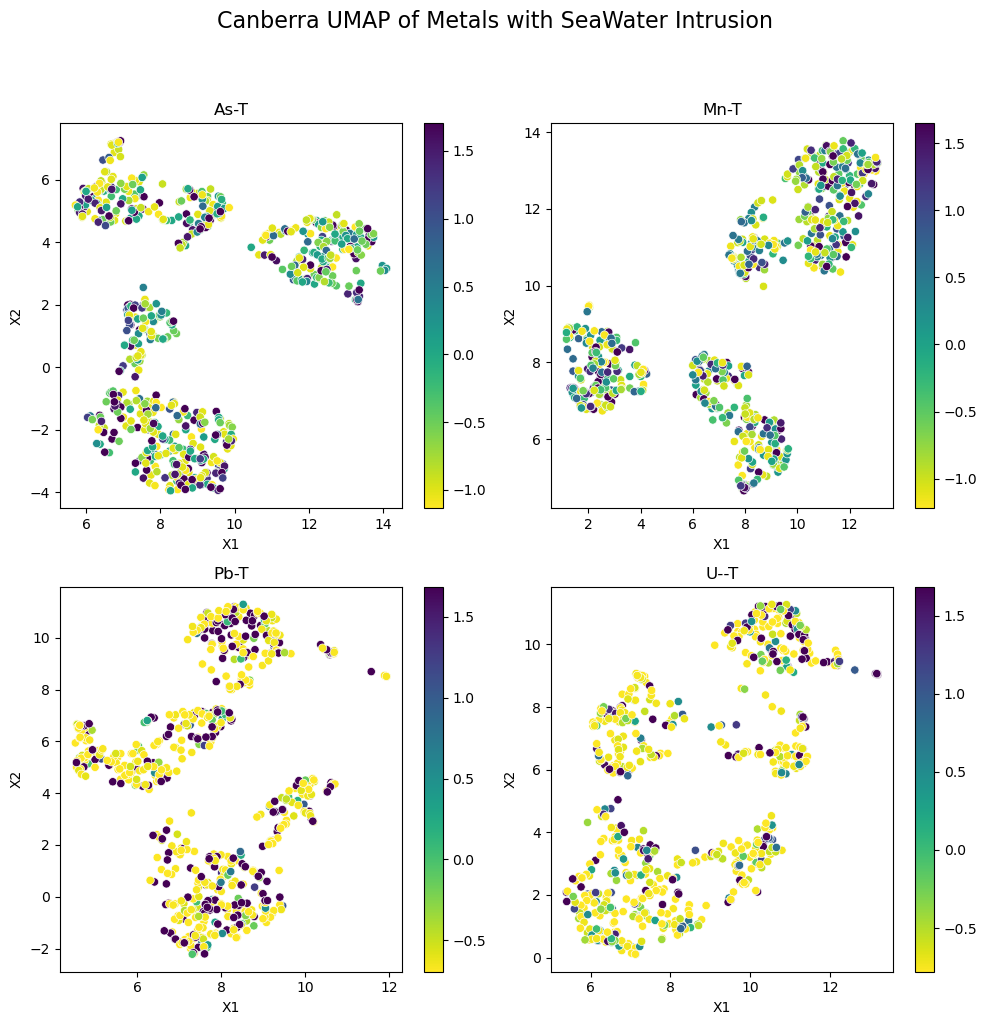

In [117]:
# Call your function with appropriate parameters
Y_listswi = [Yaswi, Ymswi, Ypswi, Yuswi]  # replace with your actual Y values
titlesswi = ['As-T', 'Mn-T', 'Pb-T', 'U--T']  # replace with your actual titles

# Call the function and get the returned figure object
figswi = supervised_umap(X=Xdataswi, Y_list=Y_listswi, titles=titlesswi)
# Set main title for the figure
figswi.suptitle('Canberra UMAP of Metals with SeaWater Intrusion', fontsize=16, y=1.02)
# Adjust layout for better appearance
figswi.tight_layout(rect=[0, 0, 1, 0.98])
# Save the figure
figswi.savefig('Figures/UMAPcanberrametalsswi.png')


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.


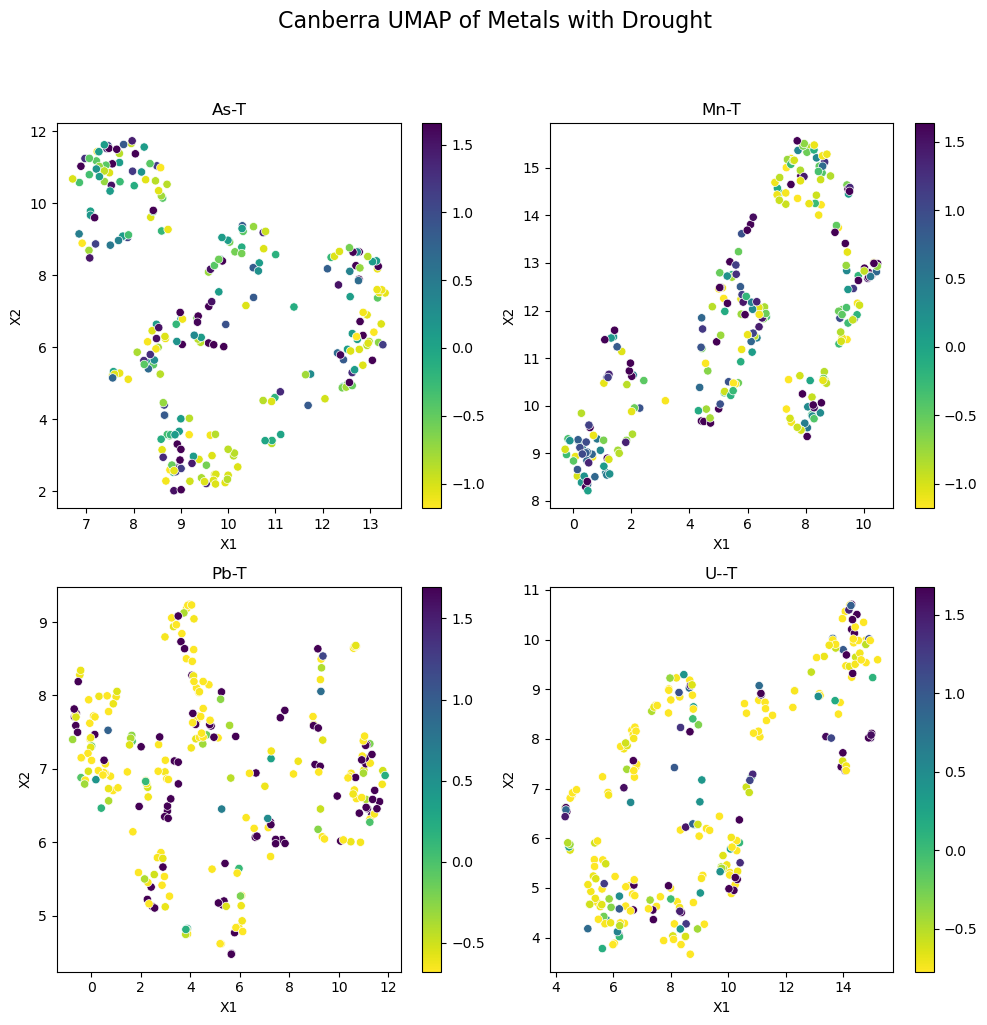

In [118]:
# Call your function with appropriate parameters
# Call your function with appropriate parameters
Y_listDrought = [YaDrought, YmDrought, YpDrought, YuDrought]  # replace with your actual Y values
titlesDrought = ['As-T', 'Mn-T', 'Pb-T', 'U--T']  # replace with your actual titles

# Call the function and get the returned figure object
figDrought = supervised_umap(X=XdataDrought, Y_list=Y_listDrought, titles=titlesDrought)
# Set main title for the figure
figDrought.suptitle('Canberra UMAP of Metals with Drought', fontsize=16, y=1.02)
# Adjust layout for better appearance
figDrought.tight_layout(rect=[0, 0, 1, 0.98])
# Save the figure
figDrought.savefig('Figures/UMAPcanberrametalsDrought.png')


In [201]:
DatatDroughtND.columns

Index(['As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T',
       'Residue Filterable 1.0u', 'Specific Conductance', 'Sulfat:D', 'pH',
       'K--T', 'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW',
       'MT', 'Aquifer Group'],
      dtype='object')

In [257]:
'''
With HDBScan

Source:
https://umap-learn.readthedocs.io/en/latest/clustering.html
https://medium.com/@ps.deeplearning.training/hdbscan-clustering-and-umap-visualisation-f31e653f7218
'''

'\nWith HDBScan\n\nSource:\n'

In [225]:
# Call your function with appropriate parameters
Y_list = [Ya, Ym, Yp, Yu]  # replace with your actual Y values
titles = ['As-T', 'Mn-T', 'Pb-T', 'U--T']  # replace with your actual titles
for i in range(len(Y_list)):
    for j in range(i + 1, len(Y_list)):
        print(f"Difference between Y_list[{i}] and Y_list[{j}]: {np.sum(Y_list[i] != Y_list[j])}")

Difference between Y_list[0] and Y_list[1]: 985
Difference between Y_list[0] and Y_list[2]: 985
Difference between Y_list[0] and Y_list[3]: 985
Difference between Y_list[1] and Y_list[2]: 985
Difference between Y_list[1] and Y_list[3]: 985
Difference between Y_list[2] and Y_list[3]: 985


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For As-T: Silhouette Score is 0.09059319645166397, Calinski-Harabasz Score is 235.9305890697597
For As-T: The ratio of non-noise points is 0.7147208121827411
For As-T: Adjusted Rand Index is 0.024893384859817708, Adjusted Mutual Information is 0.08686154246346268


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For Mn-T: Silhouette Score is 0.05637452006340027, Calinski-Harabasz Score is 150.6284093273799
For Mn-T: The ratio of non-noise points is 0.7319796954314721
For Mn-T: Adjusted Rand Index is 0.017625332296740404, Adjusted Mutual Information is 0.04225808022012492


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For Pb-T: Silhouette Score is 0.16692188382148743, Calinski-Harabasz Score is 205.17743279548952
For Pb-T: The ratio of non-noise points is 0.7137055837563452
For Pb-T: Adjusted Rand Index is 0.11941857588394332, Adjusted Mutual Information is 0.130688100880917


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For U--T: Silhouette Score is 0.08317531645298004, Calinski-Harabasz Score is 156.9091630782043
For U--T: The ratio of non-noise points is 0.6203045685279188
For U--T: Adjusted Rand Index is 0.2830820687681066, Adjusted Mutual Information is 0.28287884757772586


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)


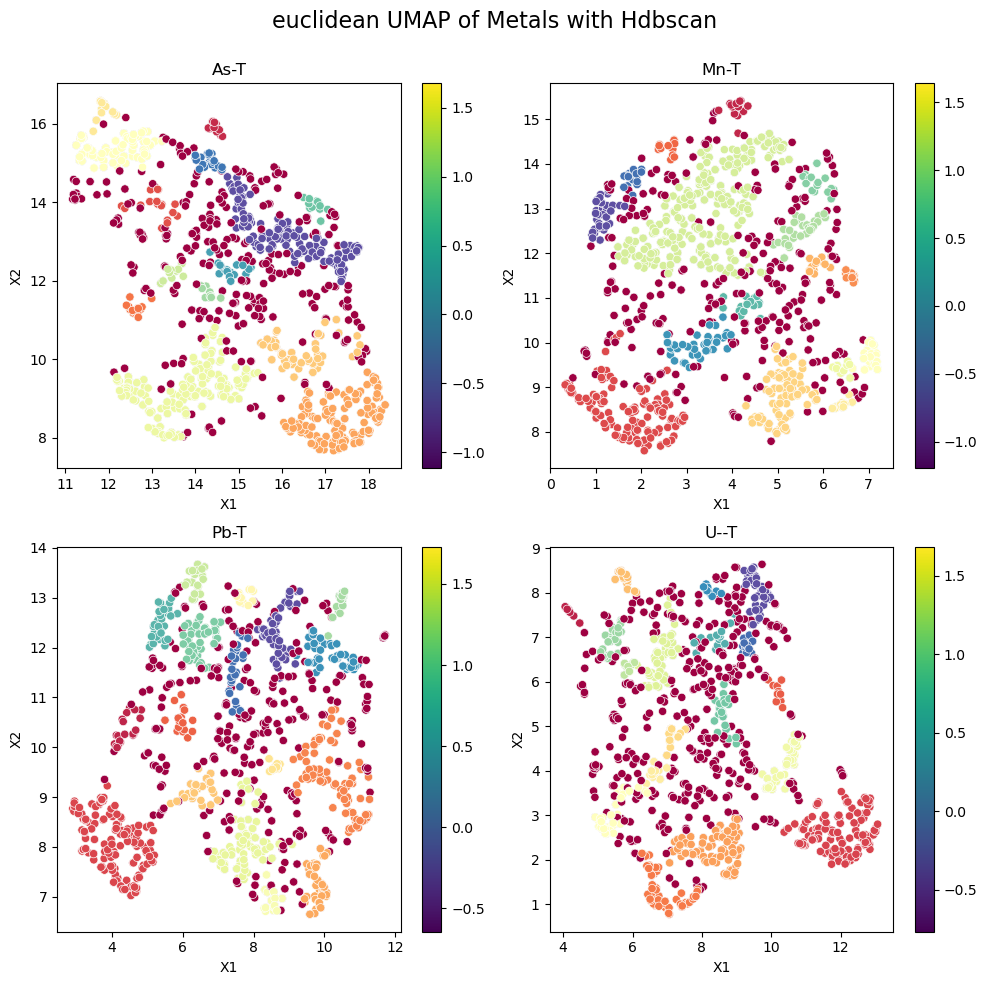

In [127]:
import matplotlib.colors as mcolors
import hdbscan
from sklearn import metrics

def supervised_umap_hdbscan(X, Y_list, titles):
    fig, axs = plt.subplots(2, 2, figsize=(10, 10))  # create a 2x2 grid of subplots
    axs = axs.ravel()  # flatten the grid to easily iterate over it

    for i, Y in enumerate(Y_list):
        manifold = umap.UMAP(
            n_neighbors=15,
            n_components=2,
            metric='euclidean',
            low_memory=True,
            min_dist = 0.1,
            random_state=42
        ).fit(
            X = X,
            y = Y
        )
        ReducedX = manifold.transform(X)

        # normalize Y values to range [0, 1] for using with the colormap
        norm = mcolors.Normalize(vmin=np.min(Y), vmax=np.max(Y))

        # create a colormap
        cmap = plt.cm.viridis

        # Create a dataframe for seaborn
        data = pd.DataFrame(ReducedX, columns=['X1', 'X2'])
        data['Y'] = Y

        # Use seaborn to create the scatterplot
        ax = sns.scatterplot(x='X1', y='X2', hue='Y', palette=cmap, data=data, ax=axs[i], legend=False)

        # Add a colorbar using matplotlib
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])  # necessary for the colorbar
        fig.colorbar(sm, ax=axs[i])

        # Set the title for this subplot
        axs[i].set_title(titles[i])

        # HDBSCAN clustering
        clusterer = hdbscan.HDBSCAN(min_cluster_size=10)
        cluster_labels = clusterer.fit_predict(ReducedX)
        data['cluster'] = cluster_labels

        # Add the clustering results to the plot
        sns.scatterplot(x='X1', y='X2', hue='cluster', data=data, ax=axs[i], palette='Spectral', legend=False)

        # Print clustering scores
        silhouette_score = metrics.silhouette_score(ReducedX, cluster_labels)
        calinski_harabasz_score = metrics.calinski_harabasz_score(ReducedX, cluster_labels)
        print(f"For {titles[i]}: Silhouette Score is {silhouette_score}, Calinski-Harabasz Score is {calinski_harabasz_score}")

        # Consider only the non-noise points
        clustered = (cluster_labels >= 0)
        ratio_non_noise = np.sum(clustered) / X.shape[0]
        print(f"For {titles[i]}: The ratio of non-noise points is {ratio_non_noise}")

        if np.sum(clustered) > 1:  # Check if there are at least 2 non-noise points
            ari = metrics.adjusted_rand_score(Y[clustered], cluster_labels[clustered])
            ami = metrics.adjusted_mutual_info_score(Y[clustered], cluster_labels[clustered])
            print(f"For {titles[i]}: Adjusted Rand Index is {ari}, Adjusted Mutual Information is {ami}")

    plt.tight_layout()
    return fig

# Call your function with appropriate parameters
Y_list = [Ya, Ym, Yp, Yu]  # replace with your actual Y values
titles = ['As-T', 'Mn-T', 'Pb-T', 'U--T']  # replace with your actual titles
fig = supervised_umap_hdbscan(X=Xdata, Y_list=Y_list, titles=titles)

# Set main title for the figure
fig.suptitle('euclidean UMAP of Metals with Hdbscan', fontsize=16)

# Adjust layout for better appearance
fig.tight_layout(rect=[0, 0, 1, 0.98])
# Save the figure
fig.savefig('Figures/UMAPeuclideanmetalshbscan.png')

plt.show()

In [87]:
!pip install hdbscan

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tables 3.8.0 requires blosc2~=2.0.0, which is not installed.



  Obtaining dependency information for cython<3,>=0.27 from https://files.pythonhosted.org/packages/3f/d6/9eed523aeaca42acbaa3e6d3850edae780dc7f8da9df1bf6a2ceb851839c/Cython-0.29.36-py2.py3-none-any.whl.metadata
   ---------------------------------------- 0.0/988.3 kB ? eta -:--:--
   --- ------------------------------------ 81.9/988.3 kB 2.2 MB/s eta 0:00:01
   ------------ --------------------------- 317.4/988.3 kB 3.9 MB/s eta 0:00:01
   ------------------------------ --------- 757.8/988.3 kB 6.0 MB/s eta 0:00:01
   ---------------------------------------- 988.3/988.3 kB 6.2 MB/s eta 0:00:00
  Attempting uninstall: cython
    Found existing installation: Cython 3.0.0
    Uninstalling Cython-3.0.0:
      Successfully uninstalled Cython-3.0.0


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For As-T: Silhouette Score is 0.36634907126426697, Calinski-Harabasz Score is 318.16287799661137
For As-T: The ratio of non-noise points is 0.9350253807106599
For As-T: Adjusted Rand Index is 0.021390010535606335, Adjusted Mutual Information is 0.0684892998545046


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For Mn-T: Silhouette Score is 0.6872124671936035, Calinski-Harabasz Score is 3183.756914282461
For Mn-T: The ratio of non-noise points is 1.0
For Mn-T: Adjusted Rand Index is -0.002578282236939887, Adjusted Mutual Information is 0.0023297840688045433


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For Pb-T: Silhouette Score is 0.20388951897621155, Calinski-Harabasz Score is 119.663931601175
For Pb-T: The ratio of non-noise points is 0.7736040609137056
For Pb-T: Adjusted Rand Index is 0.10891559315913639, Adjusted Mutual Information is 0.17703734095172582


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For U--T: Silhouette Score is 0.24122081696987152, Calinski-Harabasz Score is 177.40170030574072
For U--T: The ratio of non-noise points is 0.8294416243654822
For U--T: Adjusted Rand Index is 0.2408597961077052, Adjusted Mutual Information is 0.3468468541024036


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)


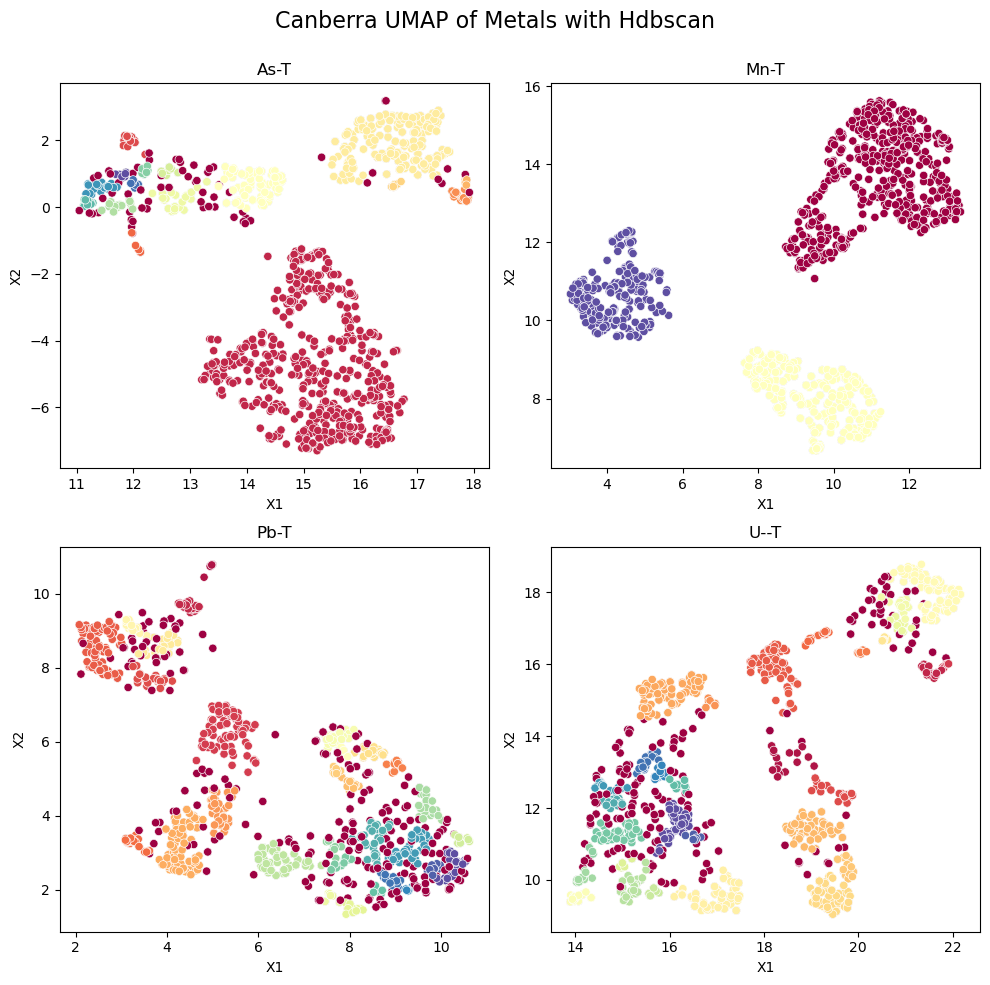

In [129]:
import matplotlib.colors as mcolors
import hdbscan
from sklearn import metrics

def supervised_umap_hdbscancan(X, Y_list, titles):
    fig, axs = plt.subplots(2, 2, figsize=(10, 10))  # create a 2x2 grid of subplots
    axs = axs.ravel()  # flatten the grid to easily iterate over it

    for i, Y in enumerate(Y_list):
        manifold = umap.UMAP(
            n_neighbors=30,
            n_components=2,
            metric='canberra',
            min_dist = 0.1,
            low_memory=True,
            random_state=42
        ).fit(
            X = X,
            y = Y
        )
        ReducedX = manifold.transform(X)

        # create a colormap
        cmap = plt.cm.viridis

        # Create a dataframe for seaborn
        data = pd.DataFrame(ReducedX, columns=['X1', 'X2'])
        data['Y'] = Y

        # Use seaborn to create the scatterplot
        ax = sns.scatterplot(x='X1', y='X2', hue='Y', palette=cmap, data=data, ax=axs[i], legend=False)

        # Set the title for this subplot
        axs[i].set_title(titles[i])

        # HDBSCAN clustering
        clusterer = hdbscan.HDBSCAN(min_cluster_size=5)
        cluster_labels = clusterer.fit_predict(ReducedX)
        data['cluster'] = cluster_labels

        # Add the clustering results to the plot
        sns.scatterplot(x='X1', y='X2', hue='cluster', data=data, ax=axs[i], palette='Spectral', legend=False)

        # Print clustering scores
        silhouette_score = metrics.silhouette_score(ReducedX, cluster_labels)
        calinski_harabasz_score = metrics.calinski_harabasz_score(ReducedX, cluster_labels)
        print(f"For {titles[i]}: Silhouette Score is {silhouette_score}, Calinski-Harabasz Score is {calinski_harabasz_score}")

        # Consider only the non-noise points
        clustered = (cluster_labels >= 0)
        ratio_non_noise = np.sum(clustered) / X.shape[0]
        print(f"For {titles[i]}: The ratio of non-noise points is {ratio_non_noise}")

        if np.sum(clustered) > 1:  # Check if there are at least 2 non-noise points
            ari = metrics.adjusted_rand_score(Y[clustered], cluster_labels[clustered])
            ami = metrics.adjusted_mutual_info_score(Y[clustered], cluster_labels[clustered])
            print(f"For {titles[i]}: Adjusted Rand Index is {ari}, Adjusted Mutual Information is {ami}")

    plt.tight_layout()
    return fig

# Call your function with appropriate parameters
Y_list = [Ya, Ym, Yp, Yu]  # replace with your actual Y values
titles = ['As-T', 'Mn-T', 'Pb-T', 'U--T']  # replace with your actual titles
fig2 = supervised_umap_hdbscancan(X=Xdata, Y_list=Y_list, titles=titles)

# Set main title for the figure
fig2.suptitle('Canberra UMAP of Metals with Hdbscan', fontsize=16)

# Adjust layout for better appearance
fig2.tight_layout(rect=[0, 0, 1, 0.98])
# Save the figure
fig2.savefig('Figures/UMAPeuclideanmetalshbscan.png')

plt.show()

C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For As-T: Silhouette Score is 0.3675306439399719, Calinski-Harabasz Score is 240.2136296061613
For As-T: The ratio of non-noise points is 0.8641732283464567
For As-T: Adjusted Rand Index is 0.051563903272535405, Adjusted Mutual Information is 0.07167400779581162


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For Mn-T: Silhouette Score is 0.45379140973091125, Calinski-Harabasz Score is 935.5308476514914
For Mn-T: The ratio of non-noise points is 0.9822834645669292
For Mn-T: Adjusted Rand Index is 0.006237820581650424, Adjusted Mutual Information is 0.0069617982124503845


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For Pb-T: Silhouette Score is 0.23684626817703247, Calinski-Harabasz Score is 312.2184278503284
For Pb-T: The ratio of non-noise points is 0.8838582677165354
For Pb-T: Adjusted Rand Index is 0.019148249079629958, Adjusted Mutual Information is 0.11035237207590792


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For U--T: Silhouette Score is 0.35008132457733154, Calinski-Harabasz Score is 324.97943267812917
For U--T: The ratio of non-noise points is 0.9133858267716536
For U--T: Adjusted Rand Index is 0.07566978363681948, Adjusted Mutual Information is 0.2262760618900446


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)


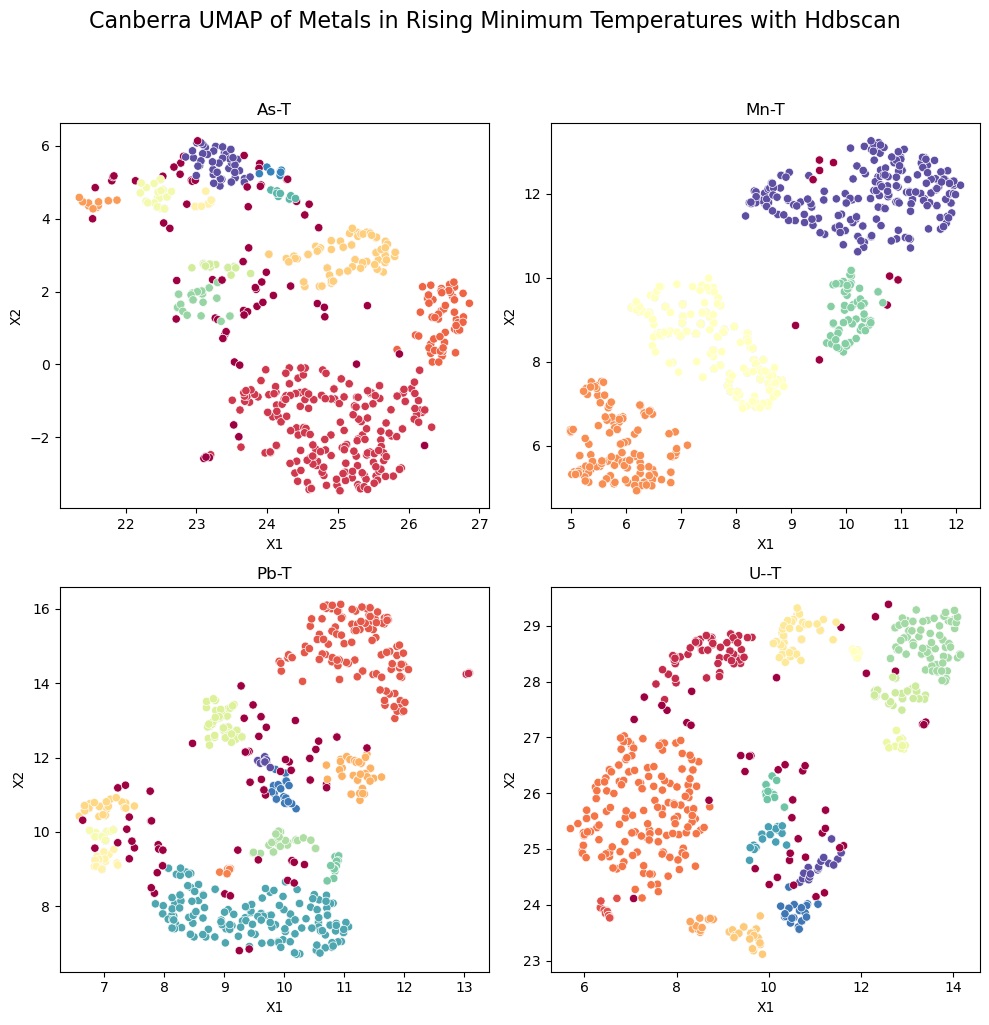

In [130]:
Y_listMT = [YaMT, YmMT, YpMT, YuMT]  # replace with your actual Y values
titlesMT = ['As-T', 'Mn-T', 'Pb-T', 'U--T']  # replace with your actual titles

# Call the function and get the returned figure object
figMTscanMT = supervised_umap_hdbscancan(X=XdataMT, Y_list=Y_listMT, titles=titlesMT)
# Set main title for the figure
figMTscanMT.suptitle('Canberra UMAP of Metals in Rising Minimum Temperatures with Hdbscan', fontsize=16, y=1.02)
# Adjust layout for better appearance
figMTscanMT.tight_layout(rect=[0, 0, 1, 0.98])
# Save the figure
figMTscanMT.savefig('Figures/UMAPcanberrametalsMTHdbscanMT.png')


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For As-T: Silhouette Score is 0.3526952862739563, Calinski-Harabasz Score is 374.99549938104013
For As-T: The ratio of non-noise points is 0.955810147299509
For As-T: Adjusted Rand Index is 0.01516975755799463, Adjusted Mutual Information is 0.026099299179750117


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For Mn-T: Silhouette Score is 0.41733336448669434, Calinski-Harabasz Score is 898.2370222658492
For Mn-T: The ratio of non-noise points is 0.9967266775777414
For Mn-T: Adjusted Rand Index is -0.0014996016350213753, Adjusted Mutual Information is -0.001313831892444331


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For Pb-T: Silhouette Score is 0.46299687027931213, Calinski-Harabasz Score is 757.0332553767407
For Pb-T: The ratio of non-noise points is 1.0
For Pb-T: Adjusted Rand Index is 0.007723863090361894, Adjusted Mutual Information is 0.04585789936268528


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For U--T: Silhouette Score is 0.2730833888053894, Calinski-Harabasz Score is 137.4529937478743
For U--T: The ratio of non-noise points is 0.8199672667757774
For U--T: Adjusted Rand Index is 0.1999960464428732, Adjusted Mutual Information is 0.3073556253959915


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)


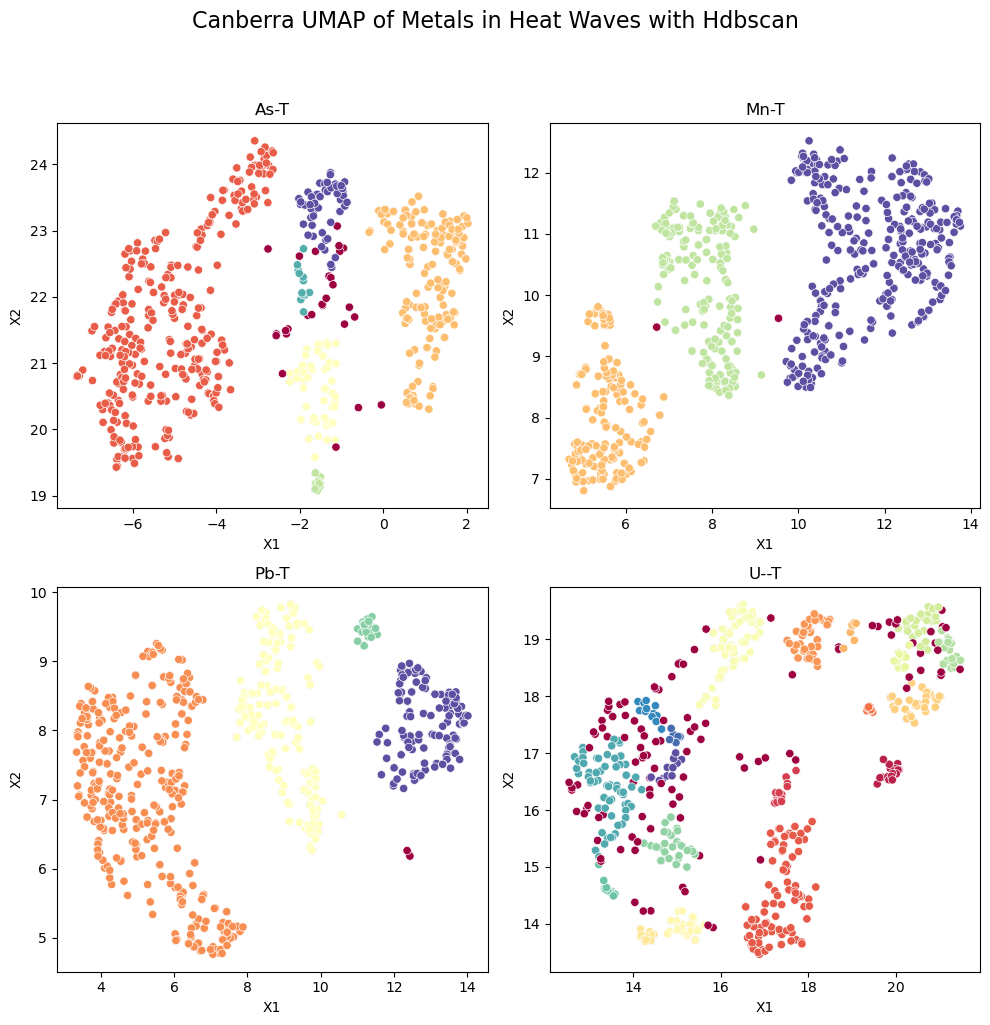

In [131]:
Y_listHW = [YaHW, YmHW, YpHW, YuHW]  # replace with your actual Y values
titlesHW = ['As-T', 'Mn-T', 'Pb-T', 'U--T']  # replace with your actual titles

# Call the function and get the returned figure object
figHWscanHW = supervised_umap_hdbscancan(X=XdataHW, Y_list=Y_listHW, titles=titlesHW)
# Set main title for the figure
figHWscanHW.suptitle('Canberra UMAP of Metals in Heat Waves with Hdbscan', fontsize=16, y=1.02)
# Adjust layout for better appearance
figHWscanHW.tight_layout(rect=[0, 0, 1, 0.98])
# Save the figure
figHWscanHW.savefig('Figures/UMAPcanberrametalsHWHdbscanHW.png')

C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For As-T: Silhouette Score is 0.437179833650589, Calinski-Harabasz Score is 338.1706273138875
For As-T: The ratio of non-noise points is 0.9098901098901099
For As-T: Adjusted Rand Index is 0.04088834801855121, Adjusted Mutual Information is 0.06225679899347116


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For Mn-T: Silhouette Score is 0.42966169118881226, Calinski-Harabasz Score is 295.591685498408
For Mn-T: The ratio of non-noise points is 0.9230769230769231
For Mn-T: Adjusted Rand Index is -0.0034030602618671255, Adjusted Mutual Information is 0.003461964646867395


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For Pb-T: Silhouette Score is 0.19536161422729492, Calinski-Harabasz Score is 62.30870809891041
For Pb-T: The ratio of non-noise points is 0.756043956043956
For Pb-T: Adjusted Rand Index is 0.19966639054922244, Adjusted Mutual Information is 0.3101115945472963


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For U--T: Silhouette Score is 0.33590173721313477, Calinski-Harabasz Score is 175.72531584135336
For U--T: The ratio of non-noise points is 0.9186813186813186
For U--T: Adjusted Rand Index is 0.04950436919431363, Adjusted Mutual Information is 0.21993592354656585


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)


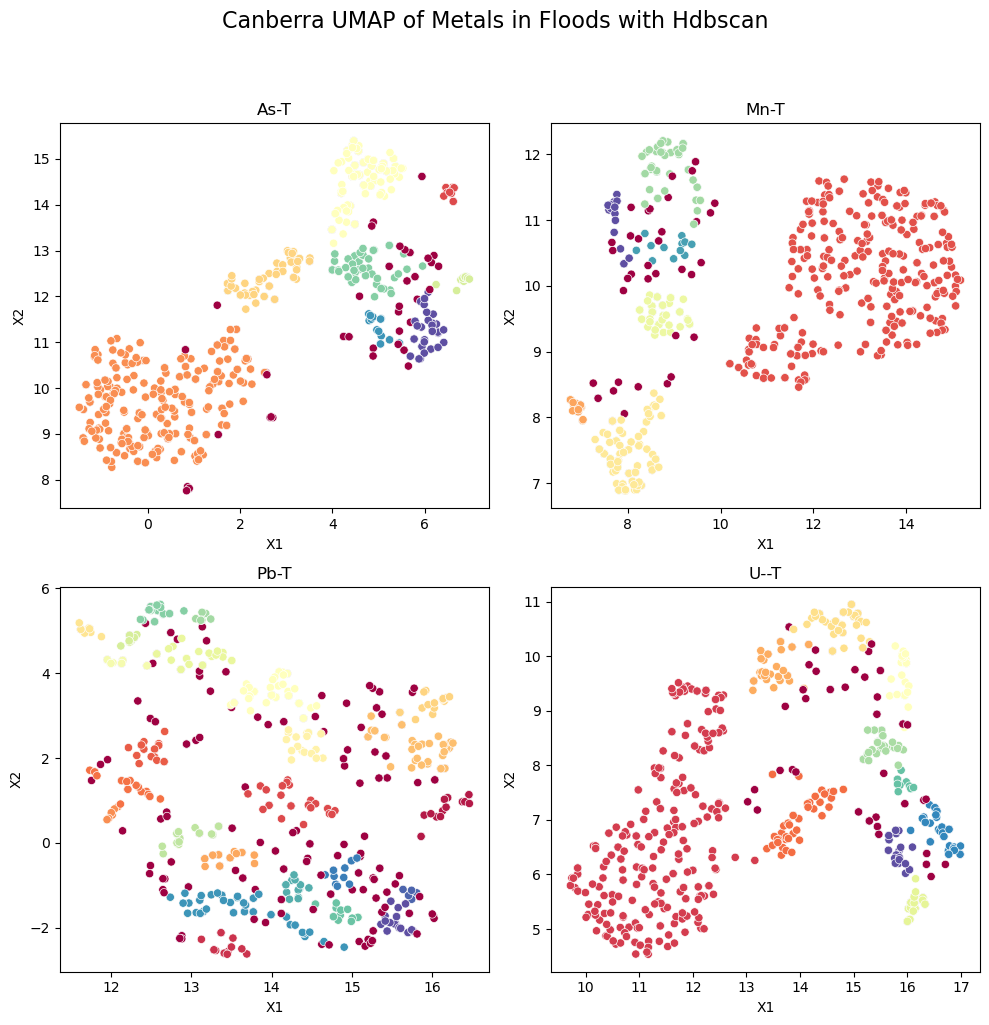

In [132]:
Y_listFlood = [YaFlood, YmFlood, YpFlood, YuFlood]  # replace with your actual Y values
titlesFlood = ['As-T', 'Mn-T', 'Pb-T', 'U--T']  # replace with your actual titles

# Call the function and get the returned figure object
figHWscanFlood = supervised_umap_hdbscancan(X=XdataFlood, Y_list=Y_listFlood, titles=titlesFlood)
# Set main title for the figure
figHWscanFlood.suptitle('Canberra UMAP of Metals in Floods with Hdbscan', fontsize=16, y=1.02)
# Adjust layout for better appearance
figHWscanFlood.tight_layout(rect=[0, 0, 1, 0.98])
# Save the figure
figHWscanFlood.savefig('Figures/UMAPcanberrametalsHdbscanFlood.png')


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For As-T: Silhouette Score is 0.26791617274284363, Calinski-Harabasz Score is 178.8141495832784
For As-T: The ratio of non-noise points is 0.8169811320754717
For As-T: Adjusted Rand Index is 0.023600959323371046, Adjusted Mutual Information is 0.09263683813152032


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For Mn-T: Silhouette Score is 0.369377076625824, Calinski-Harabasz Score is 434.18903993747335
For Mn-T: The ratio of non-noise points is 0.9584905660377359
For Mn-T: Adjusted Rand Index is -0.002000783524599102, Adjusted Mutual Information is 0.002453194418413394


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For Pb-T: Silhouette Score is 0.3839070200920105, Calinski-Harabasz Score is 350.66615561799625
For Pb-T: The ratio of non-noise points is 0.869811320754717
For Pb-T: Adjusted Rand Index is 0.085908110231247, Adjusted Mutual Information is 0.14653890605089226


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For U--T: Silhouette Score is 0.2879570424556732, Calinski-Harabasz Score is 279.2486505143683
For U--T: The ratio of non-noise points is 0.909433962264151
For U--T: Adjusted Rand Index is 0.1261301889123608, Adjusted Mutual Information is 0.19133746773340277


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)


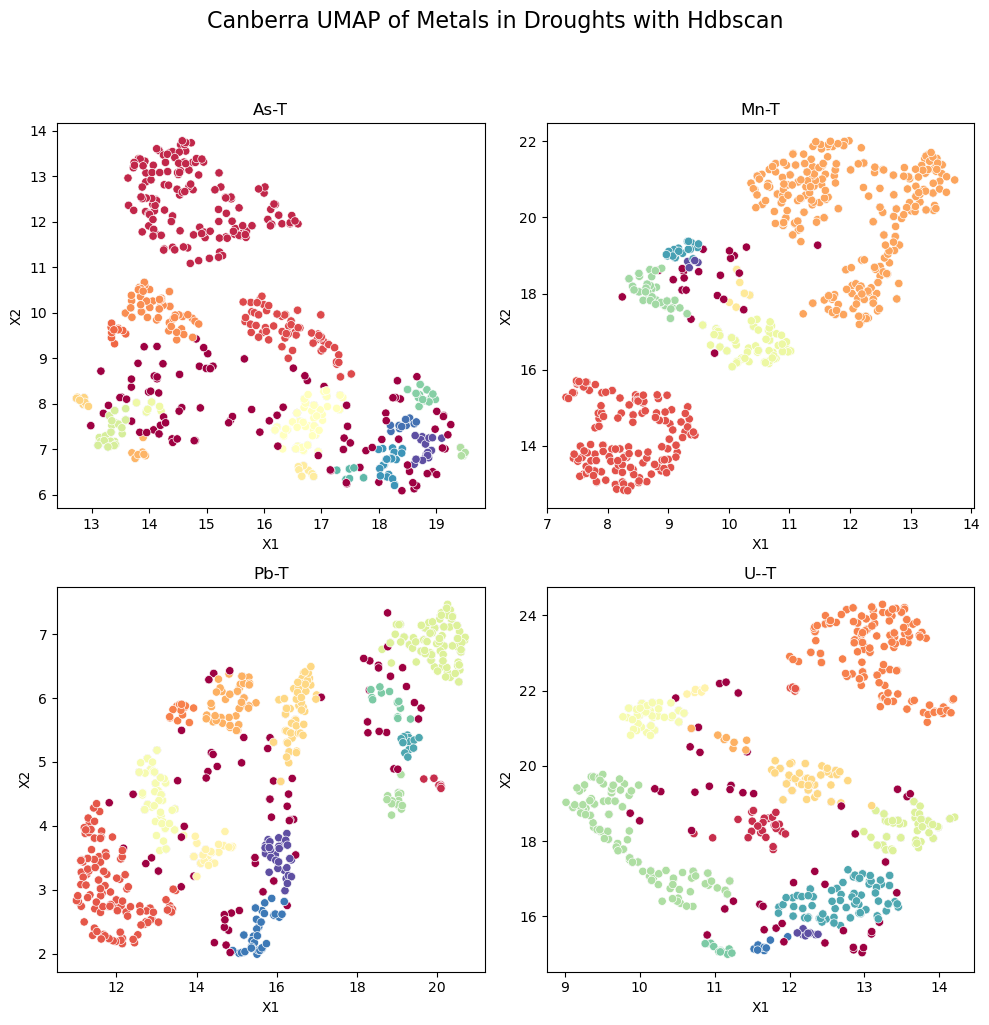

In [133]:
Y_listDrought = [YaDrought, YmDrought, YpDrought, YuDrought]  # replace with your actual Y values
titlesDrought = ['As-T', 'Mn-T', 'Pb-T', 'U--T']  # replace with your actual titles

# Call the function and get the returned figure object
figHWscanDrought = supervised_umap_hdbscancan(X=XdataDrought, Y_list=Y_listDrought, titles=titlesDrought)
# Set main title for the figure
figHWscanDrought.suptitle('Canberra UMAP of Metals in Droughts with Hdbscan', fontsize=16, y=1.02)
# Adjust layout for better appearance
figHWscanDrought.tight_layout(rect=[0, 0, 1, 0.98])
# Save the figure
figHWscanDrought.savefig('Figures/UMAPcanberrametalsHdbscanDrought.png')

C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For As-T: Silhouette Score is 0.40904831886291504, Calinski-Harabasz Score is 358.98663875826486
For As-T: The ratio of non-noise points is 0.9381327334083239
For As-T: Adjusted Rand Index is 0.01526675226435139, Adjusted Mutual Information is 0.03938451509235476


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For Mn-T: Silhouette Score is 0.4914507567882538, Calinski-Harabasz Score is 498.97380129892116
For Mn-T: The ratio of non-noise points is 0.9426321709786277
For Mn-T: Adjusted Rand Index is -0.0024668979482183025, Adjusted Mutual Information is 0.0033536374531016088


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For Pb-T: Silhouette Score is 0.232656329870224, Calinski-Harabasz Score is 175.34335687317852
For Pb-T: The ratio of non-noise points is 0.8807649043869517
For Pb-T: Adjusted Rand Index is 0.00019682290078948048, Adjusted Mutual Information is 0.07814840589506217


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


For U--T: Silhouette Score is 0.3055383265018463, Calinski-Harabasz Score is 180.54066384754472
For U--T: The ratio of non-noise points is 0.906636670416198
For U--T: Adjusted Rand Index is -0.006522063317596956, Adjusted Mutual Information is 0.14130844552231608


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:64: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)


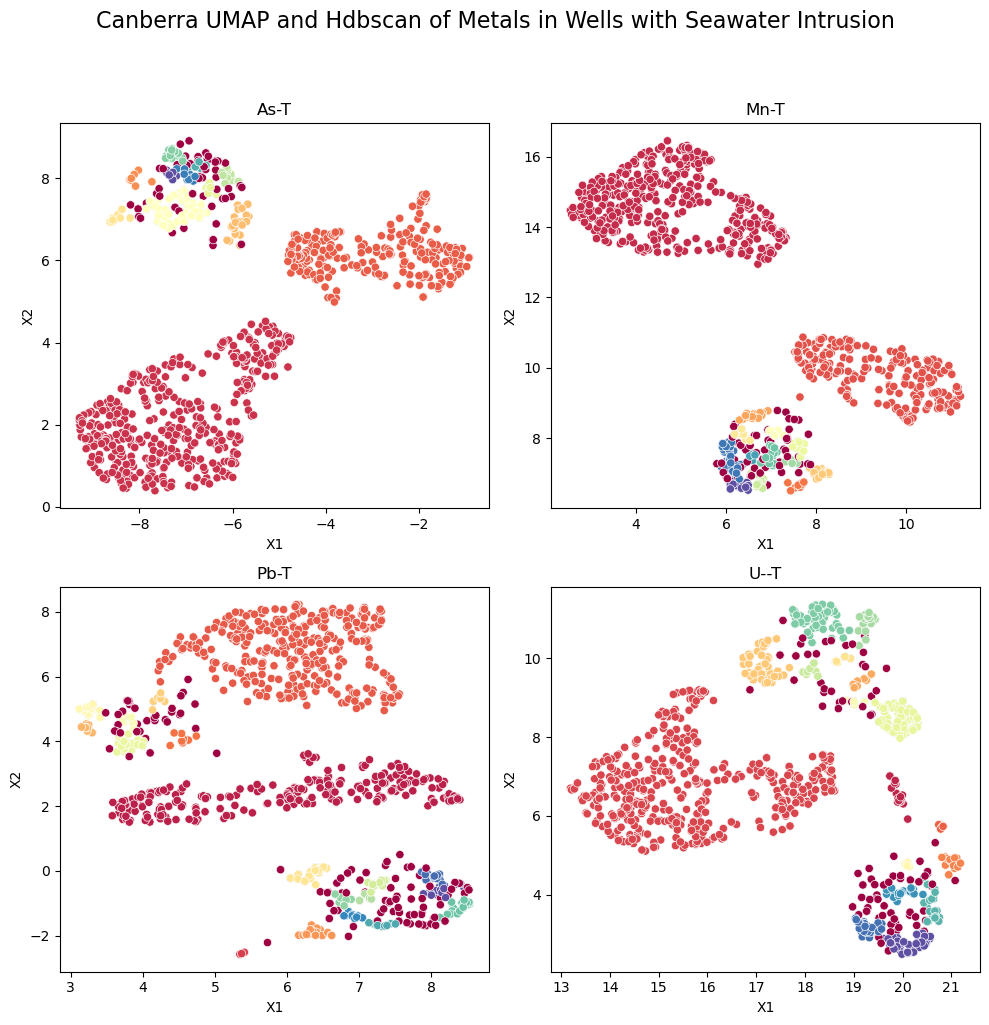

In [134]:
Y_listswi = [Yaswi, Ymswi, Ypswi, Yuswi]  # replace with your actual Y values
titlesswi = ['As-T', 'Mn-T', 'Pb-T', 'U--T']
# Call the function and get the returned figure object
figHWscanswi = supervised_umap_hdbscancan(X=Xdataswi, Y_list=Y_listswi, titles=titlesswi)
# Set main title for the figure
figHWscanswi.suptitle('Canberra UMAP and Hdbscan of Metals in Wells with Seawater Intrusion', fontsize=16, y=1.02)
# Adjust layout for better appearance
figHWscanswi.tight_layout(rect=[0, 0, 1, 0.98])
# Save the figure
figHWscanswi.savefig('Figures/UMAPcanberrametalsHdbscanswi.png')

C:\Users\Anita Taylor\anaconda3\Lib\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


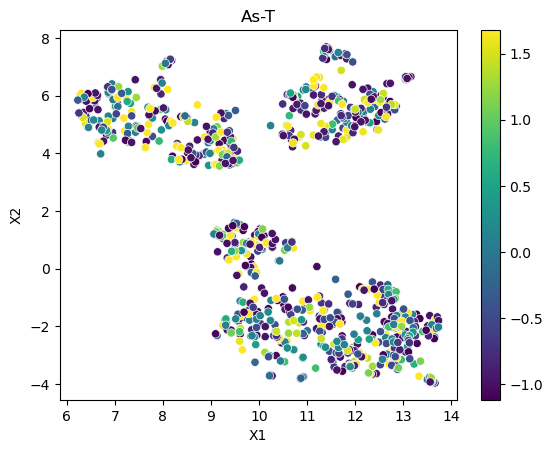

In [196]:
'''
Supervised Umap

Source: 
https://www.kaggle.com/code/bextuychiev/beautiful-umap-tutorial-on-100-dimensional-data

'''
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd

def supervised_umap(X, Y, title=''):
    manifold = umap.UMAP(
        n_neighbors=15,
        n_components=2,
        metric='canberra',
        low_memory=True,
        random_state=42
    ).fit(
        X = X,
        y = Y   
    )
    ReducedX = manifold.transform(X)

    # create a colormap
    cmap = plt.cm.viridis
    # normalize Y values to range [0, 1] for using with the colormap
    norm = mcolors.Normalize(vmin=np.min(Y), vmax=np.max(Y))

    # Create a dataframe for seaborn
    data = pd.DataFrame(ReducedX, columns=['X1', 'X2'])
    data['Y'] = Y

    # Use seaborn to create the scatterplot
    ax = sns.scatterplot(x='X1', y='X2', hue='Y', palette=cmap, data=data, legend=False)

    # Add a colorbar using matplotlib
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])  # necessary for the colorbar
    plt.colorbar(sm, ax=ax)

    plt.title(title)
    plt.show()


# Call your function with appropriate parameters

supervised_umap(X=Xdata, Y=Ya, title='As-T')
#manifoldA = umap.UMAP(random_state=42).fit(Xfulldata, Ya)
# = manifoldA.transform(Xfulldata)
#X_reducedA.reduced.shape
